# Readmission Analysis — Part 1: Descriptive & Inferential

Cohort characterization, descriptive figures, and classical inferential statistics for the
complete pediatric psychiatric cohort (**N = 2,652 patients**; 90-day (post-discharge) readmission
= 9.3%). Covers feature engineering, Table 1, demographic/clinical figures, and multivariable
logistic regression with a forest plot.

> Split from the original `Readmission_Full_Analysis.ipynb`. Predictive modeling (Random Forest,
> CatBoost, SHAP), dimensionality reduction, and advanced validation now live in
> **Part 2: `Readmission_ML_and_Advanced.ipynb`**. The two notebooks share the same imports and
> feature-engineering preamble, so each runs independently.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from catboost import CatBoostClassifier
import prince
import umap
import shap
import warnings
warnings.filterwarnings('ignore')

# ── Poster-quality global settings ──────────────────────────────────────────
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 12,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
})
BLUE, ORANGE = '#4C72B0', '#DD8452'
PALETTE = {'Not Readmitted': BLUE, 'Readmitted': ORANGE}
sns.set_style('whitegrid')

os.makedirs('figures', exist_ok=True)
print("✓ Libraries loaded. Figures will save to ./figures/")


/Users/matthewgold/code/Readmission-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Libraries loaded. Figures will save to ./figures/


In [2]:
# ── Load data ────────────────────────────────────────────────────────────────
df = pd.read_csv('annotated_psychiatric_data_complete.csv')

# ── Outcome ──────────────────────────────────────────────────────────────────
print("Readmissions value counts:")
print(df['Readmissions'].value_counts().sort_index())
df['readmitted'] = (df['Readmissions'].fillna(0) > 0).astype(int)

# ── Demographics ─────────────────────────────────────────────────────────────
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['age_group'] = pd.cut(df['age'], bins=[5, 9, 11, 13, 19],
                          labels=['6–9', '10–11', '12–13', '14+'], right=True)
df['gender_male'] = (df['GenderCode'].str.strip().str.lower() == 'male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)

# ── ACE score ────────────────────────────────────────────────────────────────
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score'] >= 4).astype(float)

# ── Restraints ───────────────────────────────────────────────────────────────
df['had_restraints'] = (pd.to_numeric(df['restraints'], errors='coerce').fillna(0) > 0).astype(int)

# ── C-SSRS flags ─────────────────────────────────────────────────────────────
# NOTE: The source CSV column is named 'Yellow flags (C-SRSS)' — a known typo in the
# raw export (letters transposed; should be C-SSRS). The column name must match the CSV
# exactly or yellow-flag coding silently returns all-zero on a refreshed export.
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow'] + df['csrss_orange'] + df['csrss_red']) > 0).astype(int)

# ── Length of stay (compute before date-quality filter) ──────────────────────
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate']  = pd.to_datetime(df['DischDate'],  errors='coerce')
df['los_days']   = (df['DischDate'] - df['VisitDate']).dt.days

# ── DATE QUALITY FILTER ───────────────────────────────────────────────────────
# Flag records with impossible or unusable dates and hold them out until reviewed.
flag_missing_visit  = df['VisitDate'].isna()
flag_missing_disch  = df['DischDate'].isna()
flag_negative_los   = df['los_days'].notna() & (df['los_days'] < 0)   # DischDate before VisitDate

flagged = df[flag_missing_visit | flag_missing_disch | flag_negative_los].copy()
flagged['flag_reason'] = ''
flagged.loc[flag_missing_visit[flagged.index], 'flag_reason'] += 'missing_VisitDate; '
flagged.loc[flag_missing_disch[flagged.index], 'flag_reason'] += 'missing_DischDate; '
flagged.loc[flag_negative_los[flagged.index], 'flag_reason']  += f'negative_LOS ({df.loc[flag_negative_los, "los_days"].min():.0f} to {df.loc[flag_negative_los, "los_days"].max():.0f} days); '

if len(flagged) > 0:
    flagged.to_csv('flagged_records_date_errors.csv', index=True)
    print(f"\n{'='*60}")
    print(f"  ⚠  DATE QUALITY FLAGS — {len(flagged)} records excluded")
    print(f"{'='*60}")
    print(f"  Missing VisitDate   : {flag_missing_visit.sum()}")
    print(f"  Missing DischDate   : {flag_missing_disch.sum()}")
    print(f"  Negative LOS        : {flag_negative_los.sum()} "
          f"(range: {df.loc[flag_negative_los,'los_days'].min():.0f} "
          f"to {df.loc[flag_negative_los,'los_days'].max():.0f} days)")
    print(f"\n  Readmission status of flagged records:")
    print(f"    Readmitted     : {flagged['readmitted'].sum()}")
    print(f"    Not readmitted : {(flagged['readmitted']==0).sum()}")
    print(f"\n  Saved for review → flagged_records_date_errors.csv")
    print(f"{'='*60}\n")
else:
    print("\n✓ No date-quality issues found.")

# Exclude flagged records from all downstream analysis
df = df[~(flag_missing_visit | flag_missing_disch | flag_negative_los)].copy()
df = df.reset_index(drop=True)

# ── Diagnostic complexity ─────────────────────────────────────────────────────
def count_csv(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(',') if x.strip()])

# NOTE: count_dsm5 is defined here for reference but is NOT used downstream.
# Unique cross-column DSM-5 category counts use unique_dsm5_count() instead,
# which deduplicates across VisitDiags and ChronicDiags columns.
def count_dsm5(s):  # unused — see unique_dsm5_count below
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(';') if x.strip()])

df['n_visit_diags']   = df['VisitDiags'].apply(count_csv)
df['n_chronic_diags'] = df['ChronicDiags'].apply(count_csv)
df['n_total_diags']   = df['n_visit_diags'] + df['n_chronic_diags']

def unique_dsm5_count(row):
    cats = set()
    for col in ['VisitDiags_DSM5Categories', 'ChronicDiags_DSM5Categories']:
        val = row.get(col, '')
        if pd.notna(val) and str(val).strip():
            cats.update(c.strip() for c in str(val).split(';') if c.strip())
    return len(cats)

df['n_dsm5_categories'] = df.apply(unique_dsm5_count, axis=1)

# ── DSM-5 category flags (Original String Matching) ───────────────────────────
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('') + ';' +
            df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()

CATEGORY_FLAGS = {
    'has_nssi':        'non-suicidal self-injury',
    'has_trauma':      'trauma and stressor',
    'has_adhd':        'adhd',
    'has_asd':         'autism spectrum',
    'has_conduct':     'conduct disorder',
    'has_depression':  'depressive disorders',
    'has_anxiety':     'anxiety disorders',
    'has_bipolar':     'bipolar',
    'has_psychotic':   'psychotic',
    'has_intellectual':'intellectual disability',
    'has_ocd':         'obsessive-compulsive',
}
for flag, kw in CATEGORY_FLAGS.items():
    df[flag] = all_dsm5.str.contains(kw, na=False).astype(int)
# ── Medical comorbidity (Original Regex) ──────────────────────────────────────
def count_medical(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return sum(1 for c in str(s).split(',') if c.strip() and not c.strip().startswith('F'))

MEDICAL_COMORBIDITY_PATTERNS = {
    'Metabolic/Obesity': ('E66',),
    'Sleep Disorder': ('G47',),
    'GI/Digestive': ('K59', 'K21'),
    'Respiratory/Allergy': ('J30', 'R06'),
    'Renal/Urologic': ('N39',),
}

def get_medical_comorbidity_types(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper() for c in str(codes).split(',') if c.strip()]
    return [
        category
        for category, prefixes in MEDICAL_COMORBIDITY_PATTERNS.items()
        if any(code.startswith(prefix) for code in code_tokens for prefix in prefixes)
    ]

df['n_medical_chronic']       = df['ChronicDiags'].apply(count_medical)
# Medical comorbidity — Feudtner Pediatric CCC-aligned chapter allowlist
# C/D/E/G/H/I/J/K/L/M/N/Q: neoplasm, blood, metabolic/endocrine, neuro, eye/ear,
# cardiovascular, respiratory, digestive, skin, musculoskeletal, renal, congenital.
# Excludes F (psychiatric), Z (social/admin/ACE), R (symptoms/signs), A/B (infectious),
# P (perinatal), S/T/V-Y (injury/external cause). Prevalence ≈42%.
_CCC_P1 = frozenset('CDEGHIJKLMNQ')
def _has_ccc_p1(codes):
    if pd.isna(codes) or str(codes).strip() == '': return 0
    return int(any(t.strip().upper() and t.strip().upper()[0] in _CCC_P1
                   for t in str(codes).split(',') if t.strip()))
df['has_medical_comorbidity'] = df['ChronicDiags'].apply(_has_ccc_p1)
df['medical_comorbidity_types'] = df['ChronicDiags'].apply(get_medical_comorbidity_types)

# ── Medical comorbidity (Emulated CCS Mapping) ────────────────────────────────
def get_pyhealth_medical_comorbidity_types_emulated(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper().replace('.', '') for c in str(codes).split(',') if c.strip()]
    types = []
    
    for c in code_tokens:
        if c.startswith(('E66', 'E4', 'E5', 'E6', 'E7', 'E8')):
            if 'Metabolic/Obesity_pyhealth' not in types: types.append('Metabolic/Obesity_pyhealth')
        if c.startswith(('G47',)):
            if 'Sleep Disorder_pyhealth' not in types: types.append('Sleep Disorder_pyhealth')
        if c.startswith(('K2', 'K3', 'K4', 'K5', 'K6', 'K7', 'K8', 'K9')):
            if 'GI/Digestive_pyhealth' not in types: types.append('GI/Digestive_pyhealth')
        if c.startswith(('J3', 'J4', 'R06', 'J8', 'J9')):
            if 'Respiratory/Allergy_pyhealth' not in types: types.append('Respiratory/Allergy_pyhealth')
        if c.startswith(('N3', 'N4', 'N1', 'N2')):
            if 'Renal/Urologic_pyhealth' not in types: types.append('Renal/Urologic_pyhealth')
    return types

df['medical_comorbidity_types_pyhealth'] = df['ChronicDiags'].apply(get_pyhealth_medical_comorbidity_types_emulated)
df['has_medical_comorbidity_pyhealth'] = (df['medical_comorbidity_types_pyhealth'].apply(len) > 0).astype(int)

# Count total non-mental health CCS categories roughly
df['n_medical_chronic_pyhealth'] = df['ChronicDiags'].apply(lambda x: sum(1 for c in str(x).split(',') if c.strip() and not c.strip().upper().startswith('F')))

print(f"✓ Feature engineering complete.")
print(f"  N = {len(df):,} (after date-quality exclusions) | "
      f"Readmitted = {df['readmitted'].sum():,} ({df['readmitted'].mean():.1%})")
print(f"  Age range: {df['age'].min():.0f}–{df['age'].max():.0f} yrs | "
      f"LOS: {df['los_days'].min():.0f}–{df['los_days'].max():.0f} days "
      f"(median {df['los_days'].median():.0f})")
print(f"  ACE score available: {df['ace_score'].notna().sum():,} "
      f"({df['ace_score'].notna().mean():.1%})")

# ── Batch-2 shared feature augmentation (suicidality-ICD, neurocognitive, distinct dx, ACE tiers, insurance, ICD chapters) ──
_allcodes = (df['VisitDiags'].fillna('')+','+df['NonSuicidialDiags'].fillna('')+','+df['ChronicDiags'].fillna('')).str.upper()
df['restraint_n'] = pd.to_numeric(df['restraints'], errors='coerce').fillna(0)
df['has_suicidal_ideation'] = _allcodes.str.contains('R45.851', regex=False).astype(int)
df['has_suicide_attempt']   = _allcodes.str.contains(r'T14\.91|Z91\.5', regex=True).astype(int)
_NEURO=['F02.80','F0280','F03.91','F0391','F05','F07.81','F0781','F09']
df['has_neurocognitive']=(all_dsm5.str.contains('neurocognitive',na=False)|_allcodes.apply(lambda s: any(c in s for c in _NEURO))).astype(int)
def _distinct_codes(r):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=r.get(col,'')
        if pd.notna(v) and str(v).strip(): s.update(t.strip().upper() for t in str(v).split(',') if t.strip())
    return len(s)
df['n_distinct_diagnoses']=df.apply(_distinct_codes,axis=1)
# physical ACE-Associated Health Conditions (ACEs Aware pediatric); psychiatric AAHCs excluded (circular in this cohort)
_PHYS_AAHC={'Asthma':('J45',),'Overweight/obesity':('E66','Z684'),'Allergy/atopy':('J30','T784'),
 'Eczema/dermatitis':('L20','L21','L23','L24','L25','L27','L28','L30'),'Urticaria':('L50',),
 'Headache/migraine':('R51','G43','G44'),'Somatic symptoms':('R10','R11','R42','K59'),
 'Sleep disturbance':('G47',),'Enuresis/encopresis':('N3944','R32','F980','R15','F981'),'Failure to thrive':('R6251','R627','R633')}
_norm=_allcodes.str.replace('.','',regex=False)
def _has_pref(prefixes):
    return pd.Series([any(any(t.startswith(p) for t in s.split(',')) for p in prefixes) for s in _norm], index=df.index)
_ace_cond=pd.DataFrame({k:_has_pref(v) for k,v in _PHYS_AAHC.items()})
df['has_ace_condition']=(_ace_cond.sum(axis=1)>0).astype(int)
def _ace_tier(a,c):
    if pd.isna(a): return np.nan
    if a==0: return 'Low'
    if a>=4: return 'High'
    return 'High' if c==1 else 'Intermediate'
df['ace_risk_tier']=[_ace_tier(a,c) for a,c in zip(df['ace_score'],df['has_ace_condition'])]
df['high_ace_expanded']=df['ace_risk_tier'].map({'Low':0,'Intermediate':0,'High':1})
# richer insurance categories: Public / Commercial / Military / Tribal-IHS / Other
def _ins_cat(x):
    s=str(x).upper()
    if any(k in s for k in ['AHCCCS','MEDICAID','MAGELLAN','HCIC','AFMC','CREWS']): return 'Public'
    if any(k in s for k in ['TRICARE','CHAMPVA']): return 'Military'
    if any(k in s for k in ['GILA RIVER','NAVAJO','INDIAN HEALTH','IHS']): return 'Tribal/IHS'
    if pd.isna(x) or s in ('NAN','','OUT OF NETWORK','SP SPECIAL ARRANGEMENT','CHARITY CARE'): return 'Other/unknown'
    return 'Commercial'
df['insurance_cat5']=df['Insurance'].apply(_ins_cat)
# ICD-10 chapter set per patient (first-letter based)
_ICD_CH={'A':'Infectious','B':'Infectious','C':'Neoplasm','D':'Blood/neoplasm','E':'Endocrine/metabolic','F':'Mental/behavioral',
 'G':'Nervous','H':'Eye/ear','I':'Circulatory','J':'Respiratory','K':'Digestive','L':'Skin','M':'Musculoskeletal',
 'N':'Genitourinary','P':'Perinatal','Q':'Congenital','R':'Symptoms/signs','S':'Injury','T':'Injury/poisoning','Z':'Status/Z-codes'}
def _chapters(r):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=r.get(col,'')
        if pd.notna(v) and str(v).strip():
            for t in str(v).split(','):
                t=t.strip().upper()
                if t: s.add(_ICD_CH.get(t[0],'Other'))
    return s
df['_icd_chapters']=df.apply(_chapters,axis=1)
print(f"  +Batch-2 features: suicidal_ideation={int(df.has_suicidal_ideation.sum())}, neurocognitive={int(df.has_neurocognitive.sum())}, "
      f"distinct_dx median={df.n_distinct_diagnoses.median():.0f}, high_ACE(expanded)={int(df.high_ace_expanded.fillna(0).sum())}; "
      f"insurance5={dict(df.insurance_cat5.value_counts())}")


Readmissions value counts:
Readmissions
0    2406
1     219
2      25
3       2
Name: count, dtype: int64

✓ No date-quality issues found.
✓ Feature engineering complete.
  N = 2,652 (after date-quality exclusions) | Readmitted = 246 (9.3%)
  Age range: 5–12 yrs | LOS: 1–112 days (median 8)
  ACE score available: 1,569 (59.2%)
  +Batch-2 features: suicidal_ideation=1346, neurocognitive=8, distinct_dx median=6, high_ACE(expanded)=996; insurance5={'Public': np.int64(1631), 'Commercial': np.int64(896), 'Military': np.int64(65), 'Other/unknown': np.int64(45), 'Tribal/IHS': np.int64(15)}


In [3]:

# ── Table 1: Detailed Descriptive Statistics ──────────────────────────────────
from scipy.stats import ttest_ind, chi2_contingency

def get_stats(vals, total, is_ra=False):
    r = {}
    r['N (%)'] = f"{len(vals)} ({100*len(vals)/total:.1f}%)"
    
    # Readmissions
    r['# Readmissions, mean±SD'] = f"{vals['Readmissions'].mean():.2f} ± {vals['Readmissions'].std():.2f}"
    
    # ACE Score
    ace_n = vals['ace_score'].notna().sum()
    r['ACE score collected, n(%)'] = f"{ace_n} ({100*ace_n/len(vals):.1f}%)"
    r['ACE score, mean±SD'] = f"{vals['ace_score'].mean():.1f} ± {vals['ace_score'].std():.1f}"
    r['ACE score, median'] = f"{vals['ace_score'].median():.1f}"
    
    # LOS
    r['LOS, mean±SD'] = f"{vals['los_days'].mean():.1f} ± {vals['los_days'].std():.1f}"
    r['LOS, median'] = f"{vals['los_days'].median():.1f}"
    
    # Diagnoses
    r['# Visit diags, mean±SD'] = f"{vals['n_visit_diags'].mean():.1f} ± {vals['n_visit_diags'].std():.1f}"
    r['# Visit diags, median']  = f"{vals['n_visit_diags'].median():.1f}"
    r['# Chronic diags, mean±SD'] = f"{vals['n_chronic_diags'].mean():.1f} ± {vals['n_chronic_diags'].std():.1f}"
    r['# Chronic diags, median']  = f"{vals['n_chronic_diags'].median():.1f}"
    r['# NSSI diags, mean±SD'] = f"{vals['has_nssi'].mean():.1f} ± {vals['has_nssi'].std():.1f}"
    
    # Medical comorbidity categories are not mutually exclusive.
    if 'medical_comorbidity_types' in vals.columns:
        med_types = vals['medical_comorbidity_types']
    else:
        med_types = vals['ChronicDiags'].apply(get_medical_comorbidity_types)
    all_types = [t for sublist in med_types for t in sublist]
    type_counts = pd.Series(all_types).value_counts()
    for t, count in type_counts.items():
        r[f'Medical: {t}, n(%)'] = f"{count} ({100*count/len(vals):.1f}%)"
        
    return r

ra  = df[df['readmitted'] == 1]
nra = df[df['readmitted'] == 0]
total_n = len(df)

table1_data = {
    'Not Readmitted': get_stats(nra, total_n),
    'Readmitted': get_stats(ra, total_n)
}
table1 = pd.DataFrame(table1_data).T
table1.to_csv('figures/Table1_descriptive.csv')
print(table1.to_string())

                       N (%) # Readmissions, mean±SD ACE score collected, n(%) ACE score, mean±SD ACE score, median LOS, mean±SD LOS, median # Visit diags, mean±SD # Visit diags, median # Chronic diags, mean±SD # Chronic diags, median # NSSI diags, mean±SD Medical: GI/Digestive, n(%) Medical: Metabolic/Obesity, n(%) Medical: Sleep Disorder, n(%) Medical: Respiratory/Allergy, n(%) Medical: Renal/Urologic, n(%)
Not Readmitted  2406 (90.7%)             0.00 ± 0.00              1429 (59.4%)          3.7 ± 2.6               3.0    9.9 ± 7.1         8.0              4.3 ± 2.3                   4.0                5.1 ± 5.3                     4.0             0.4 ± 0.5                  211 (8.8%)                       190 (7.9%)                    155 (6.4%)                         116 (4.8%)                     96 (4.0%)
Readmitted        246 (9.3%)             1.12 ± 0.35               140 (56.9%)          4.0 ± 2.5               4.0   10.2 ± 4.1        10.0              4.4 ± 2.2           

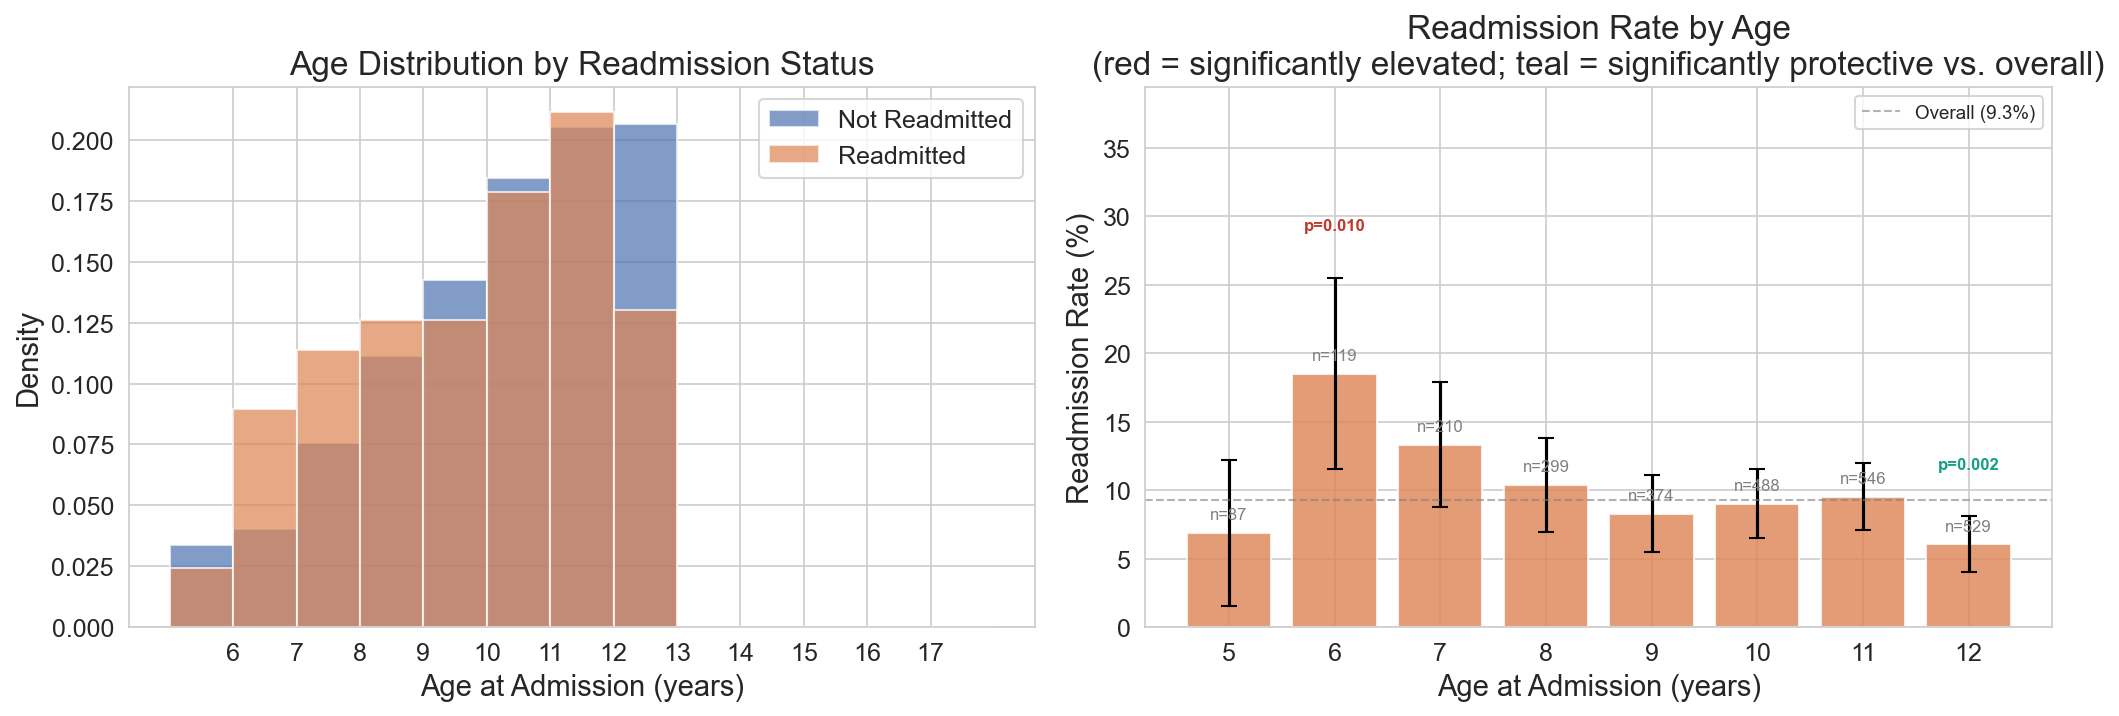

✓ Fig 1 saved

Protective age groups (rate < overall 9.3%, p<0.05):
  Age 12: 6.0% readmission rate — p=0.002

Elevated-risk age groups (rate > overall 9.3%, p<0.05):
  Age 6: 18.5% readmission rate — p=0.010


In [4]:

# ── Fig 1: Age distribution + readmission rate by age ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for status, color, label in [(0, BLUE, 'Not Readmitted'), (1, ORANGE, 'Readmitted')]:
    subset = df[df['readmitted'] == status]['age'].dropna()
    axes[0].hist(subset, bins=range(5, 19), alpha=0.7, color=color, label=label,
                 edgecolor='white', density=True)
axes[0].set_xlabel('Age at Admission (years)')
axes[0].set_ylabel('Density')
axes[0].set_title('Age Distribution by Readmission Status')
axes[0].legend()
axes[0].set_xticks(range(6, 18))

age_ra = df.groupby('age')['readmitted'].agg(['mean', 'count']).reset_index()
age_ra.columns = ['age', 'rate', 'n']
age_ra = age_ra[age_ra['n'] >= 10].reset_index(drop=True)
from statsmodels.stats.proportion import proportions_ztest
ci = 1.96 * np.sqrt(age_ra['rate'] * (1 - age_ra['rate']) / age_ra['n'])
overall_rate = df['readmitted'].mean()

# Classify each age: elevated (red), protective (teal), or ns
sig_labels, sig_colors = [], []
for i, row in age_ra.iterrows():
    _, p = proportions_ztest(row['rate'] * row['n'], row['n'], value=overall_rate)
    if p < 0.05:
        if row['rate'] > overall_rate:
            sig_labels.append('p<0.001' if p < 0.001 else f'p={p:.3f}')
            sig_colors.append('#c0392b')   # red = elevated risk
        else:
            sig_labels.append('p<0.001' if p < 0.001 else f'p={p:.3f}')
            sig_colors.append('#16a085')   # teal = protective
    else:
        sig_labels.append('')
        sig_colors.append(None)

axes[1].bar(age_ra['age'], age_ra['rate'] * 100, color=ORANGE, alpha=0.8, edgecolor='white')
axes[1].errorbar(age_ra['age'], age_ra['rate'] * 100, yerr=ci * 100,
                 fmt='none', color='black', capsize=4, linewidth=1.5)
axes[1].axhline(overall_rate * 100, color='gray', linestyle='--', linewidth=1,
                alpha=0.6, label=f'Overall ({overall_rate:.1%})')

for i, row in age_ra.iterrows():
    bar_top = row['rate'] * 100
    ci_top  = ci.iloc[i] * 100
    axes[1].text(row['age'], bar_top + 1.0,
                 f"n={int(row['n'])}", ha='center', fontsize=8, color='gray')
    if sig_labels[i]:
        axes[1].text(row['age'], bar_top + ci_top + 3.5,
                     sig_labels[i], color=sig_colors[i],
                     ha='center', fontsize=8, fontweight='bold')

max_top = (age_ra['rate'] * 100 + ci * 100).max()
axes[1].set_ylim(0, max_top * 1.55)
axes[1].set_xlabel('Age at Admission (years)')
axes[1].set_ylabel('Readmission Rate (%)')
axes[1].set_title('Readmission Rate by Age\n(red = significantly elevated; teal = significantly protective vs. overall)')
axes[1].set_xticks(age_ra['age'].astype(int))
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('figures/Fig1_age_distribution.png')
plt.show()
print("✓ Fig 1 saved")
print(f"\nProtective age groups (rate < overall {overall_rate:.1%}, p<0.05):")
for i, row in age_ra.iterrows():
    if sig_colors[i] == '#16a085':
        print(f"  Age {int(row['age'])}: {row['rate']:.1%} readmission rate — {sig_labels[i]}")
print(f"\nElevated-risk age groups (rate > overall {overall_rate:.1%}, p<0.05):")
for i, row in age_ra.iterrows():
    if sig_colors[i] == '#c0392b':
        print(f"  Age {int(row['age'])}: {row['rate']:.1%} readmission rate — {sig_labels[i]}")


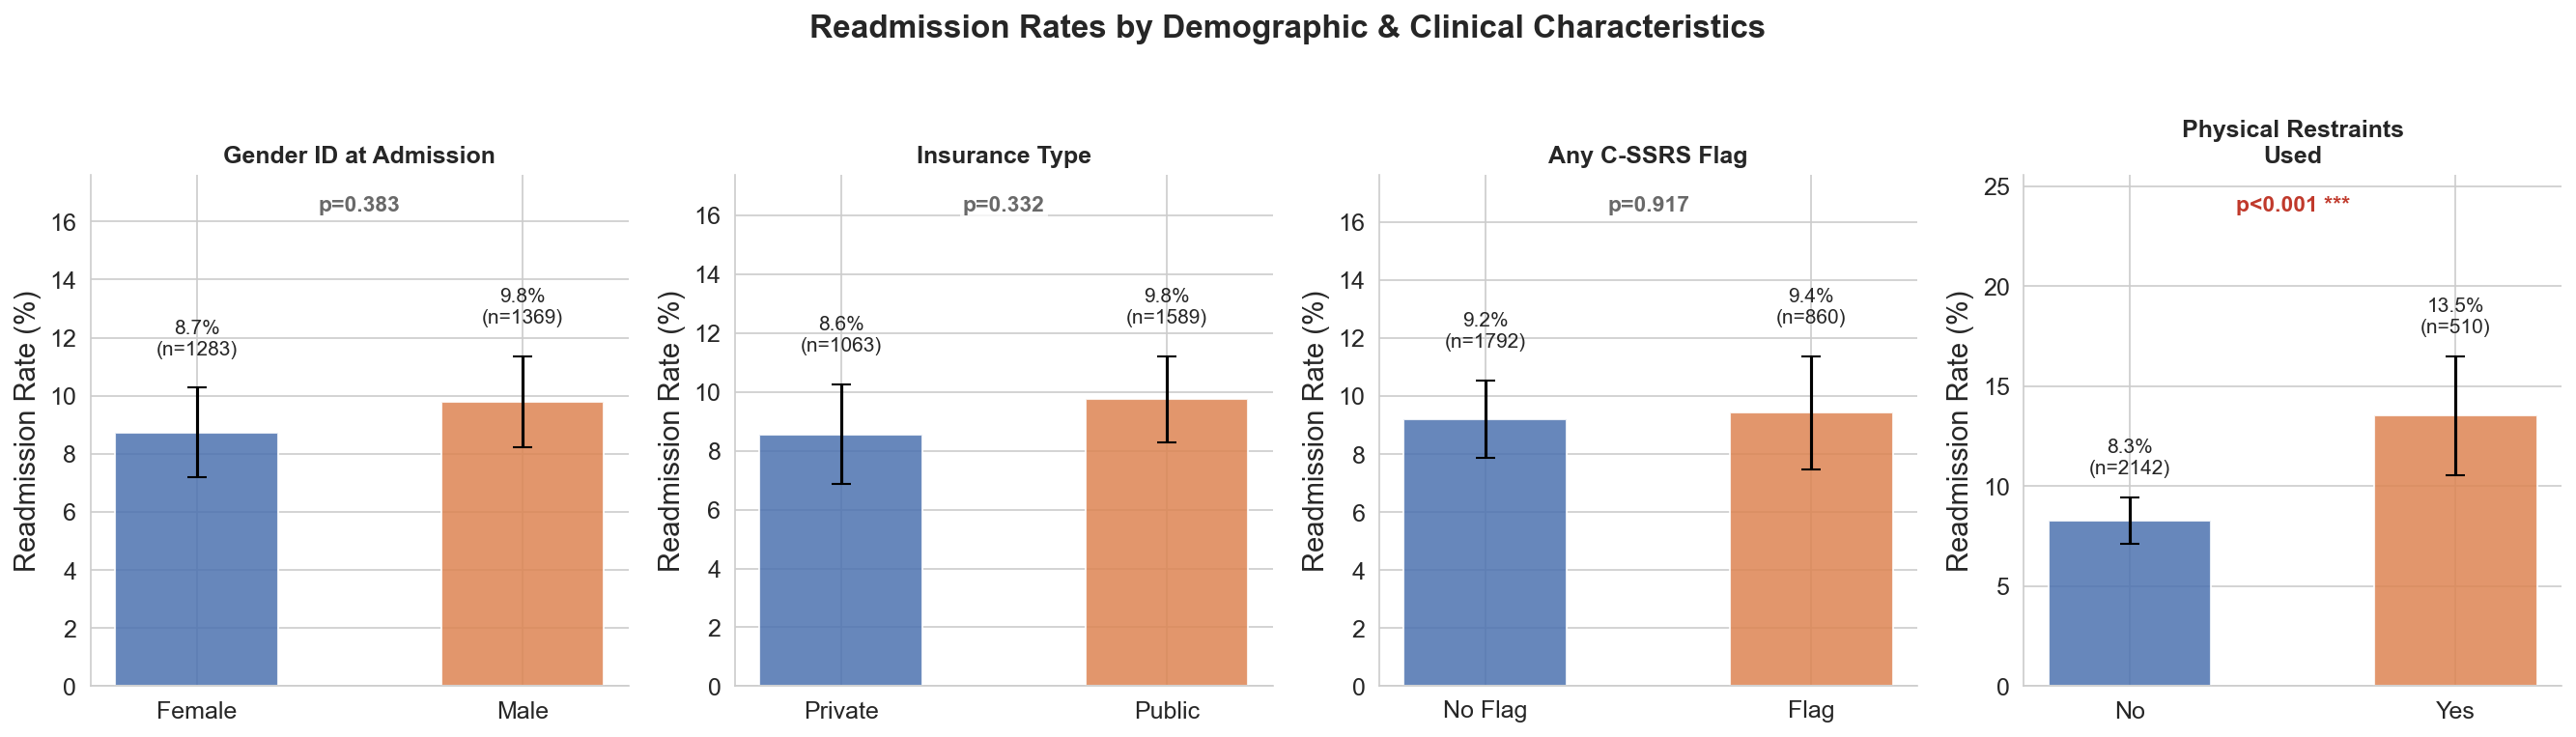

✓ Fig 2 saved


In [5]:

# ── Fig 2: Demographics panel (gender, insurance, C-SSRS, restraints) ─────────
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

binary_vars = [
    ('gender_male',      'Gender ID at Admission',       ['Female', 'Male']),
    ('insurance_public', 'Insurance Type',               ['Private', 'Public']),
    ('csrss_any',        'Any C-SSRS Flag',              ['No Flag', 'Flag']),
    ('had_restraints',   'Physical Restraints\nUsed',    ['No', 'Yes']),
]

for ax, (col, title, xlabels) in zip(axes, binary_vars):
    res  = df.groupby(col)['readmitted'].agg(['mean', 'count'])
    rates = res['mean'] * 100
    ns    = res['count']
    err   = 1.96 * np.sqrt(res['mean'] * (1 - res['mean']) / ns) * 100

    from scipy.stats import chi2_contingency
    tab = pd.crosstab(df[col], df['readmitted'])
    _, p, _, _ = chi2_contingency(tab)
    p_str = f'p={p:.3f}' if p >= 0.001 else 'p<0.001'
    if col == 'had_restraints' and p < 0.001:
        p_str += ' ***'
    p_color = '#c0392b' if p < 0.05 else 'dimgray'

    colors = [BLUE, ORANGE]
    bars = ax.bar(xlabels, rates.values, yerr=err.values, capsize=5,
                  color=colors, alpha=0.85, edgecolor='white', width=0.5)

    # Place label ABOVE the CI cap (rate + err + gap)
    for bar, n, rate, e in zip(bars, ns.values, rates.values, err.values):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + e + 1.0,
                f'{rate:.1f}%\n(n={n})', ha='center', va='bottom', fontsize=10)

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.text(0.5, 0.96, p_str, transform=ax.transAxes,
            ha='center', va='top', fontsize=11, fontweight='bold', color=p_color,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.75, pad=1.5))
    ax.set_ylabel('Readmission Rate (%)')
    ax.set_ylim(0, (rates.values + err.values).max() * 1.55)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Readmission Rates by Demographic & Clinical Characteristics',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig2_demographics_panel.png')
plt.show()
print("✓ Fig 2 saved")

In [6]:
# Fig 2b removed — ACE ≥4/≤3 binary comparison superseded by
# the ACE score boxplot (cell 9) and ACEs Aware risk tier (cell 17).
print("Fig 2b: skipped (redundant with boxplot + risk tier analysis)")


Fig 2b: skipped (redundant with boxplot + risk tier analysis)


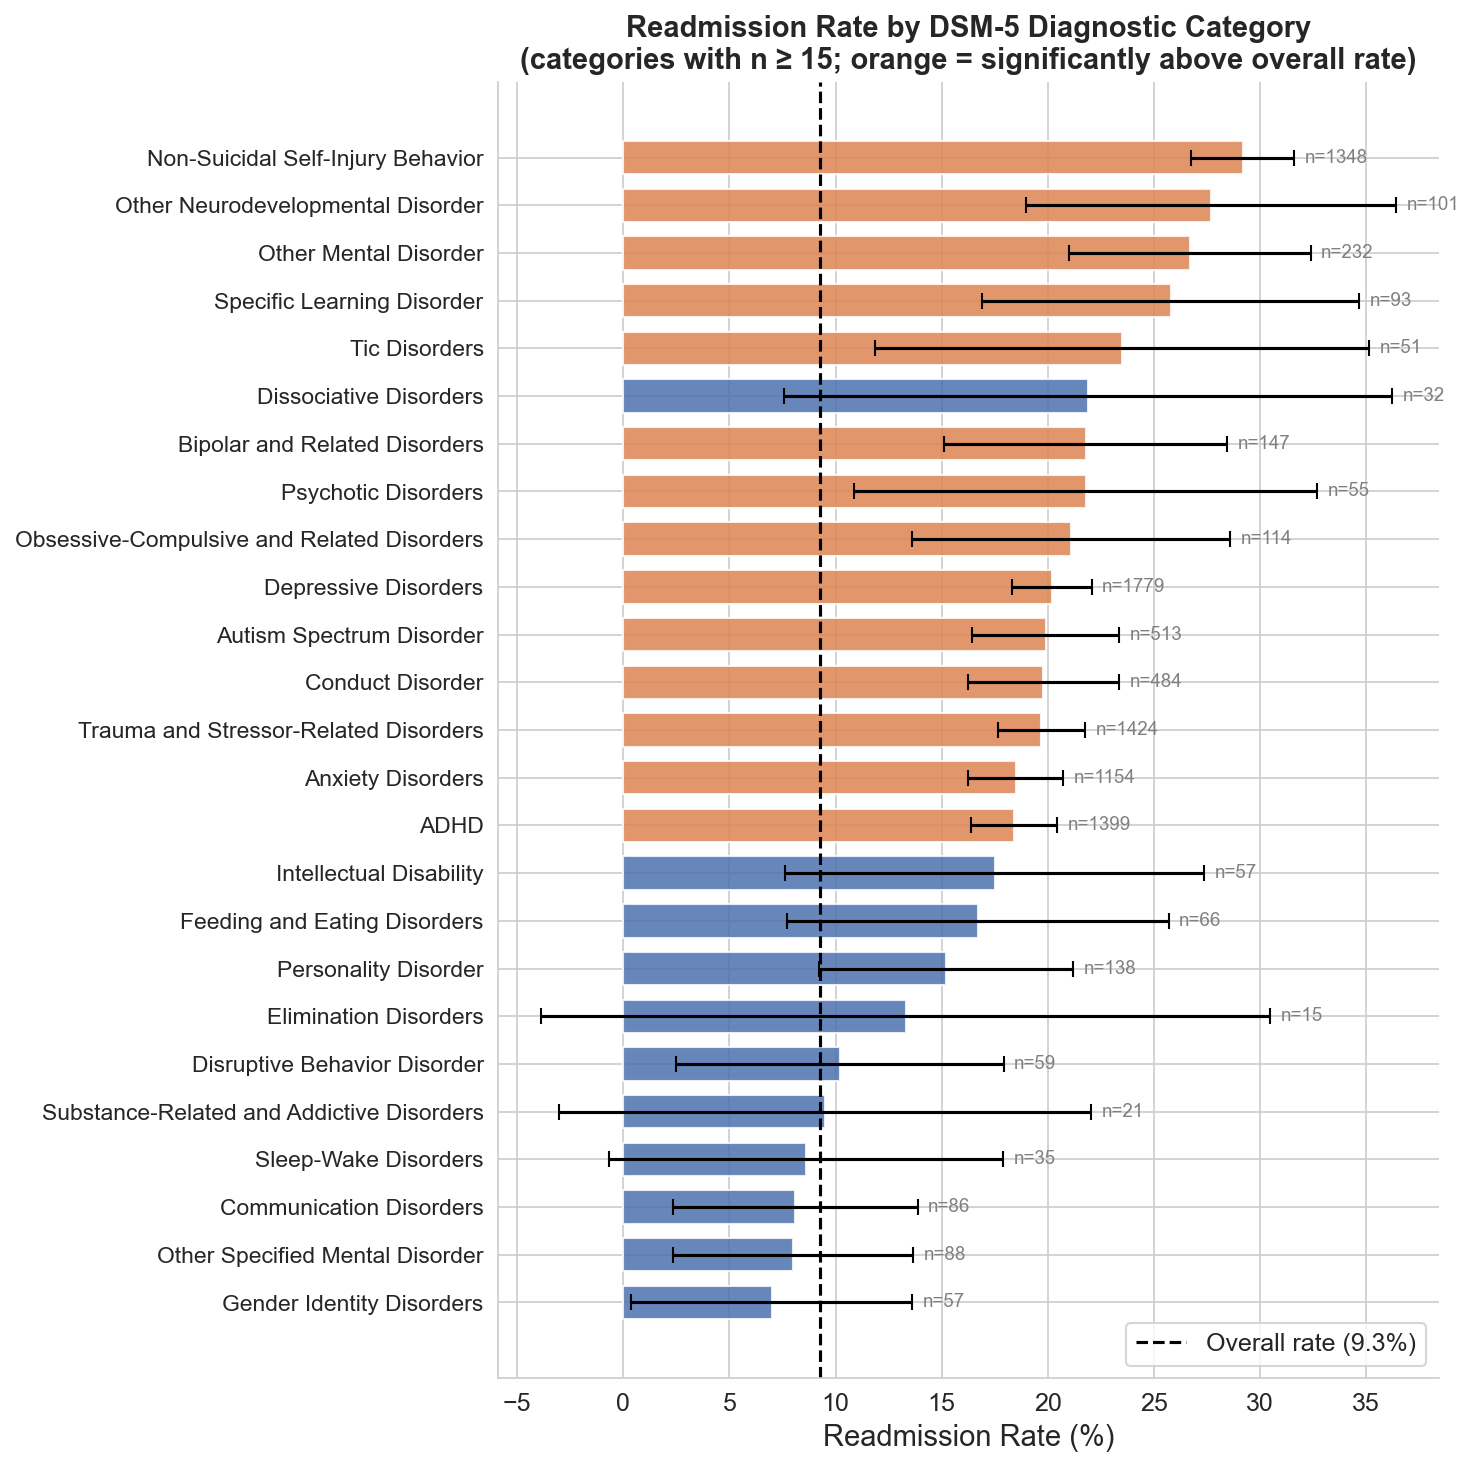

✓ Fig 3 saved


In [7]:

# ── Fig 3: Readmission rate by DSM-5 category (horizontal dot plot) ────────────
dsm5_long = pd.read_csv('DSM5_Readmission_Analysis.csv')
dsm5_long.columns = ['category', 'readmit_n', 'total_n', 'rate']
dsm5_long = dsm5_long.dropna(subset=['rate'])
dsm5_long = dsm5_long[dsm5_long['total_n'] >= 15]
dsm5_long = dsm5_long.sort_values('rate', ascending=True).reset_index(drop=True)

overall_rate = df['readmitted'].mean() * 100

# Confidence intervals
dsm5_long['p'] = dsm5_long['rate'] / 100
dsm5_long['ci'] = 1.96 * np.sqrt(dsm5_long['p'] * (1 - dsm5_long['p']) / dsm5_long['total_n']) * 100

# Orange only if lower CI bound strictly exceeds overall rate (significantly elevated)
dsm5_long['color'] = [
    ORANGE if (row['rate'] - row['ci']) > overall_rate else BLUE
    for _, row in dsm5_long.iterrows()
]

fig, ax = plt.subplots(figsize=(10, 10))
y_pos = range(len(dsm5_long))

ax.barh(y_pos, dsm5_long['rate'], xerr=dsm5_long['ci'], color=dsm5_long['color'],
        alpha=0.85, edgecolor='white', height=0.7,
        error_kw={'capsize': 4, 'linewidth': 1.5, 'ecolor': 'black'})

ax.set_yticks(y_pos)
ax.set_yticklabels(dsm5_long['category'], fontsize=11)
ax.axvline(overall_rate, color='black', linestyle='--',
           linewidth=1.5, label=f"Overall rate ({overall_rate:.1f}%)")

for i, (_, row) in enumerate(dsm5_long.iterrows()):
    ax.text(row['rate'] + row['ci'] + 0.5, i, f"n={int(row['total_n'])}",
            va='center', fontsize=9, color='gray')

ax.set_xlabel('Readmission Rate (%)')
ax.set_title('Readmission Rate by DSM-5 Diagnostic Category\n(categories with n ≥ 15; orange = significantly above overall rate)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/Fig3_readmission_by_dsm5.png')
plt.show()
print("✓ Fig 3 saved")


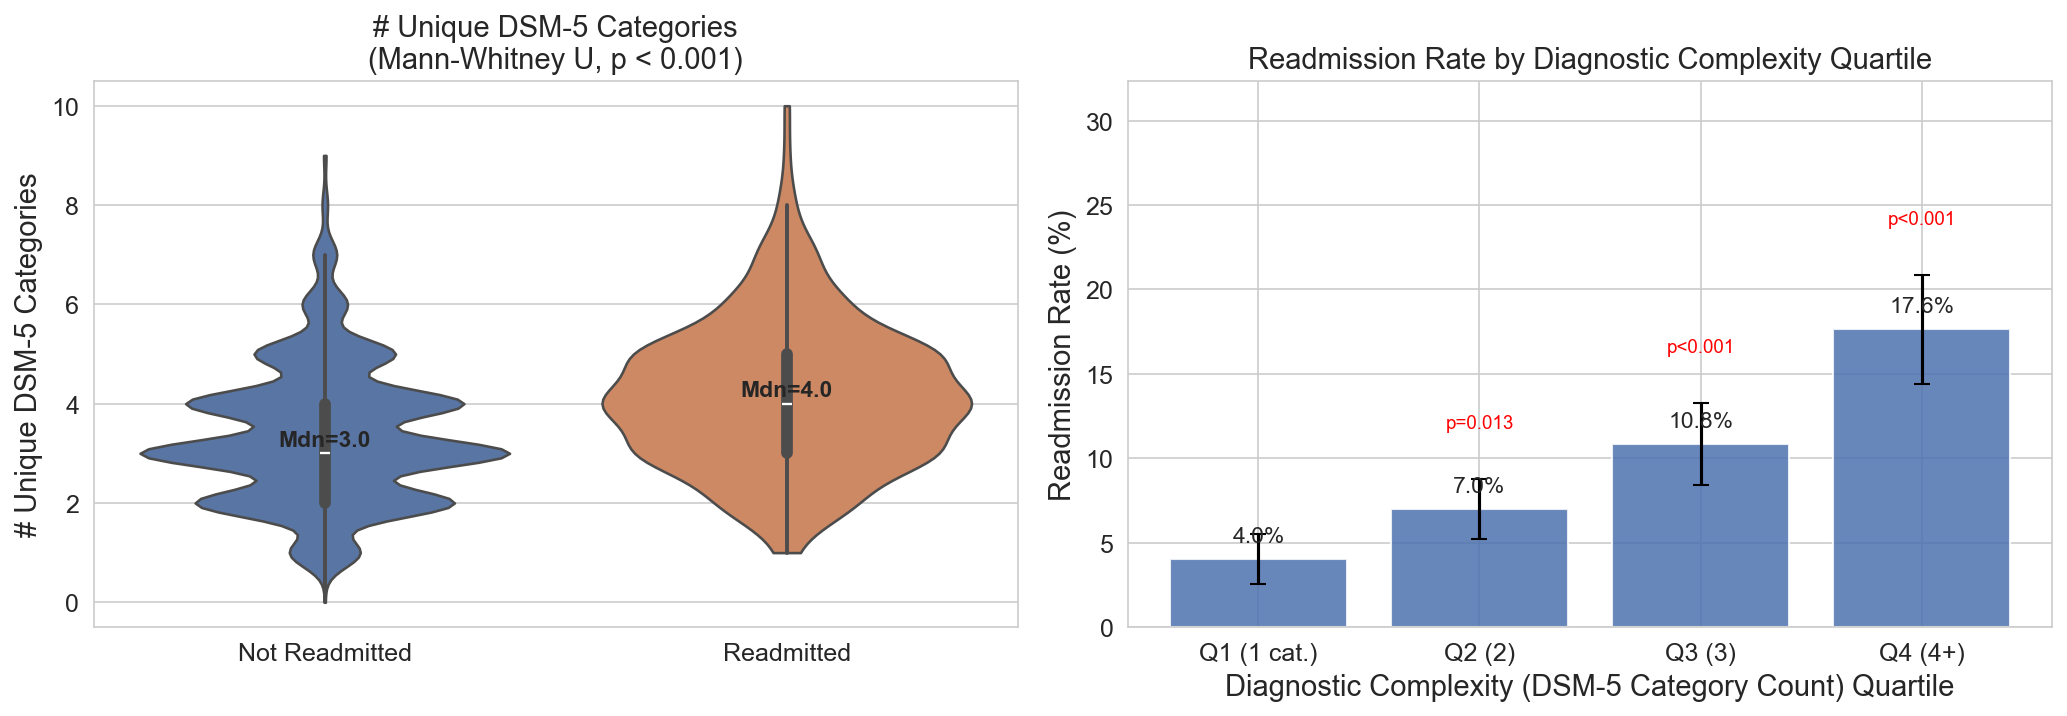

✓ Fig 4 saved


In [8]:

# ── Fig 4: Diagnostic complexity (# DSM-5 categories) by readmission ──────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: violin plot of DSM-5 category count
plot_df = df[['n_dsm5_categories', 'readmitted']].copy()
plot_df['Status'] = plot_df['readmitted'].map({0: 'Not Readmitted', 1: 'Readmitted'})

sns.violinplot(data=plot_df, x='Status', y='n_dsm5_categories',
               palette=PALETTE, inner='box', ax=axes[0], cut=0)
for i, (status, color) in enumerate([(0, BLUE), (1, ORANGE)]):
    med = df[df['readmitted'] == status]['n_dsm5_categories'].median()
    axes[0].text(i, med + 0.15, f'Mdn={med:.1f}', ha='center', fontsize=11, fontweight='bold')

u, p = stats.mannwhitneyu(
    df[df['readmitted']==1]['n_dsm5_categories'],
    df[df['readmitted']==0]['n_dsm5_categories'],
    alternative='two-sided'
)
p_str = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
axes[0].set_title(f'# Unique DSM-5 Categories\n(Mann-Whitney U, {p_str})', fontsize=14)
axes[0].set_xlabel('')
axes[0].set_ylabel('# Unique DSM-5 Categories')

# Right: readmission rate by complexity quartile
df['complexity_q'] = pd.qcut(df['n_dsm5_categories'], q=4,
                              labels=['Q1 (1 cat.)', 'Q2 (2)', 'Q3 (3)', 'Q4 (4+)'],
                              duplicates='drop')
q_rate = df.groupby('complexity_q', observed=True)['readmitted'].agg(['mean', 'count']).reset_index()
q_rate.columns = ['quartile', 'rate', 'n']
ci = 1.96 * np.sqrt(q_rate['rate'] * (1 - q_rate['rate']) / q_rate['n'])

bars = axes[1].bar(q_rate['quartile'], q_rate['rate'] * 100,
                   color=BLUE, alpha=0.85, edgecolor='white')
axes[1].errorbar(q_rate['quartile'], q_rate['rate'] * 100, yerr=ci * 100,
                 fmt='none', color='black', capsize=4, linewidth=1.5)

from statsmodels.stats.proportion import proportions_ztest
q1_rate = q_rate.iloc[0]['rate']
q1_n    = int(q_rate.iloc[0]['n'])

# Compute max top for ylim before annotating
max_top = max(q_rate['rate'].values * 100 + ci.values * 100)
axes[1].set_ylim(0, max_top * 1.55)

for idx, (bar, row_data) in enumerate(zip(bars, q_rate.itertuples())):
    rate_pct = row_data.rate * 100
    ci_pct   = ci.iloc[idx] * 100
    axes[1].text(bar.get_x() + bar.get_width()/2, rate_pct + 1,
                 f"{rate_pct:.1f}%", ha='center', fontsize=11)
    if idx > 0:
        _, p_q = proportions_ztest(
            [int(round(row_data.rate * row_data.n)), int(round(q1_rate * q1_n))],
            [int(row_data.n), q1_n]
        )
        p_label = 'p<0.001' if p_q < 0.001 else f'p={p_q:.3f}'
        color = 'red' if p_q < 0.05 else 'gray'
        axes[1].text(bar.get_x() + bar.get_width()/2,
                     rate_pct + ci_pct + 3,
                     p_label, ha='center', fontsize=9, color=color)

axes[1].set_xlabel('Diagnostic Complexity (DSM-5 Category Count) Quartile')
axes[1].set_ylabel('Readmission Rate (%)')
axes[1].set_title('Readmission Rate by Diagnostic Complexity Quartile', fontsize=14)

plt.tight_layout()
plt.savefig('figures/Fig4_diagnostic_complexity.png')
plt.show()
print("✓ Fig 4 saved")


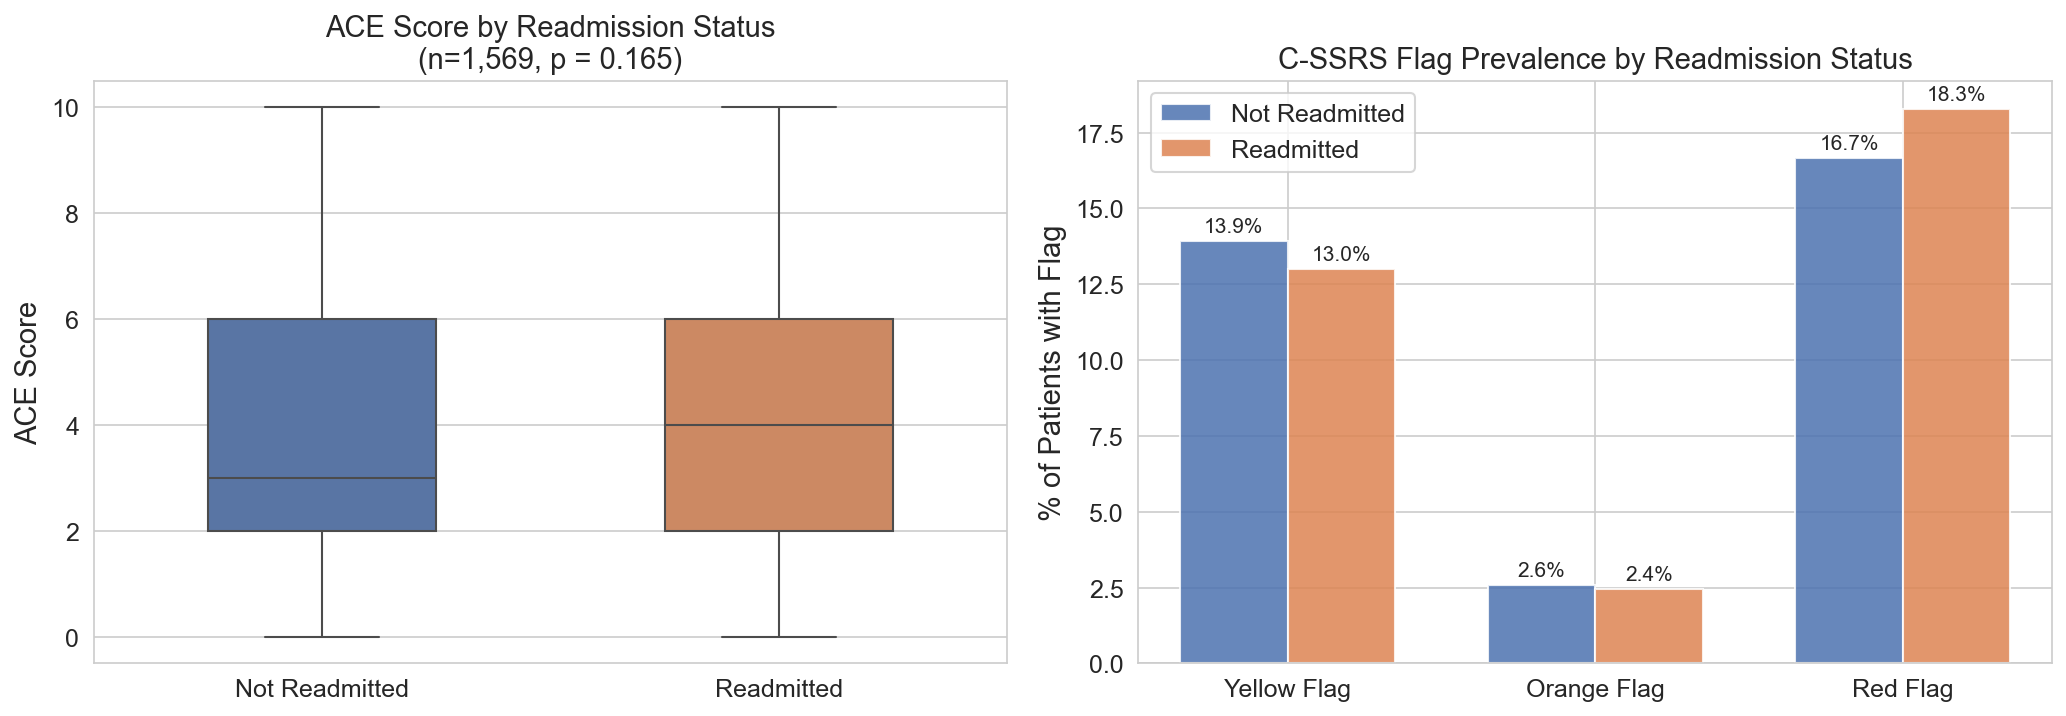

✓ Fig 5 saved


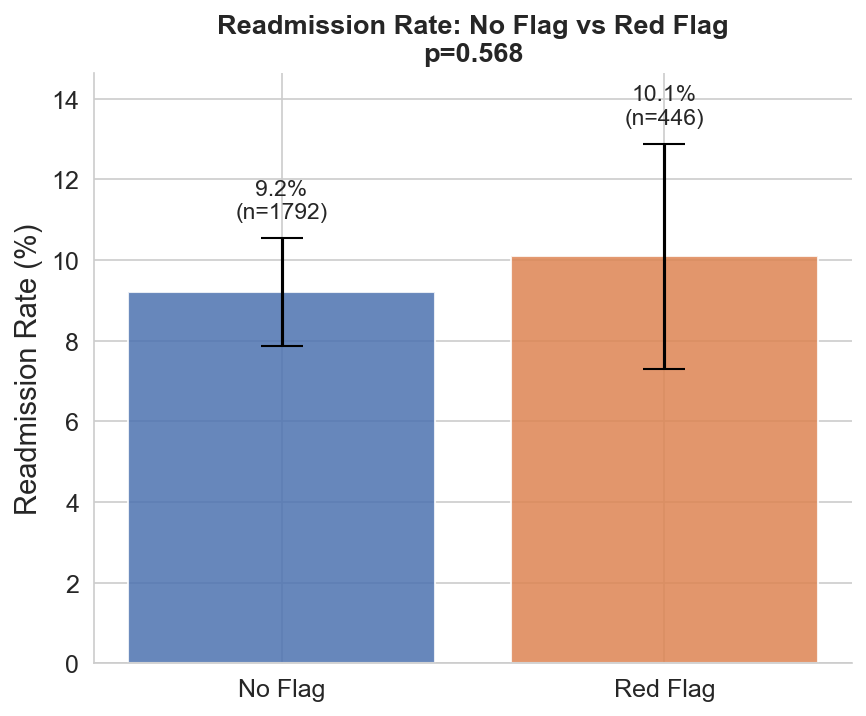

✓ Fig 5b saved


In [9]:

# ── Fig 5: ACE score + C-SSRS flags detail ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: ACE score by readmission (boxplot, only where measured)
ace_df = df[df['ace_score'].notna()][['ace_score', 'readmitted']].copy()
ace_df['Status'] = ace_df['readmitted'].map({0: 'Not Readmitted', 1: 'Readmitted'})
sns.boxplot(data=ace_df, x='Status', y='ace_score', palette=PALETTE,
            width=0.5, flierprops={'marker': 'o', 'alpha': 0.4}, ax=axes[0])
u, p = stats.mannwhitneyu(ace_df[ace_df['readmitted']==1]['ace_score'],
                           ace_df[ace_df['readmitted']==0]['ace_score'],
                           alternative='two-sided')
p_str = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
axes[0].set_title(f'ACE Score by Readmission Status\n(n={len(ace_df):,}, {p_str})', fontsize=14)
axes[0].set_xlabel('')
axes[0].set_ylabel('ACE Score')

# Right: C-SSRS flag levels
flag_cols   = ['csrss_yellow', 'csrss_orange', 'csrss_red']
flag_labels = ['Yellow Flag', 'Orange Flag', 'Red Flag']
x = np.arange(len(flag_cols))
width = 0.35

ra_rates  = [ra[c].mean() * 100 for c in flag_cols]
nra_rates = [nra[c].mean() * 100 for c in flag_cols]

b1 = axes[1].bar(x - width/2, nra_rates, width, color=BLUE,   alpha=0.85, label='Not Readmitted', edgecolor='white')
b2 = axes[1].bar(x + width/2, ra_rates,  width, color=ORANGE, alpha=0.85, label='Readmitted', edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(flag_labels)
axes[1].set_ylabel('% of Patients with Flag')
axes[1].set_title('C-SSRS Flag Prevalence by Readmission Status', fontsize=14)
axes[1].legend()
for bar, val in zip(list(b1) + list(b2), nra_rates + ra_rates):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('figures/Fig5_ace_csrss.png')
plt.show()
print("✓ Fig 5 saved")

# Specific comparison: No flag vs Red Flag
from statsmodels.stats.proportion import proportions_ztest
no_flag_r  = df[df['csrss_any']==0]['readmitted'].mean() * 100
red_flag_r = df[df['csrss_red']==1]['readmitted'].mean() * 100
ns_5    = [len(df[df['csrss_any']==0]), len(df[df['csrss_red']==1])]
rates_5 = [no_flag_r, red_flag_r]
errs_5  = [1.96 * np.sqrt((r/100)*(1-r/100)/n)*100 for r, n in zip(rates_5, ns_5)]
count_5 = [df[df['csrss_any']==0]['readmitted'].sum(), df[df['csrss_red']==1]['readmitted'].sum()]
_, p_5  = proportions_ztest(count_5, ns_5)
p_label_5 = 'p<0.001' if p_5 < 0.001 else f'p={p_5:.3f}'

fig_comp, ax_comp = plt.subplots(figsize=(6, 5))
ax_comp.bar(['No Flag', 'Red Flag'], rates_5, yerr=errs_5, color=[BLUE, ORANGE], capsize=10,
            alpha=0.85, edgecolor='white')
for i, (rate, n) in enumerate(zip(rates_5, ns_5)):
    ax_comp.text(i, rate + errs_5[i] + 0.5, f'{rate:.1f}%\n(n={n})', ha='center', fontsize=11)
ax_comp.set_ylabel('Readmission Rate (%)')
ax_comp.set_title(f'Readmission Rate: No Flag vs Red Flag\n{p_label_5}', fontsize=13, fontweight='bold')
ax_comp.set_ylim(0, max(rates_5) * 1.45)
ax_comp.spines['top'].set_visible(False)
ax_comp.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Fig5b_no_flag_vs_red_flag.png')
plt.show()
print("✓ Fig 5b saved")


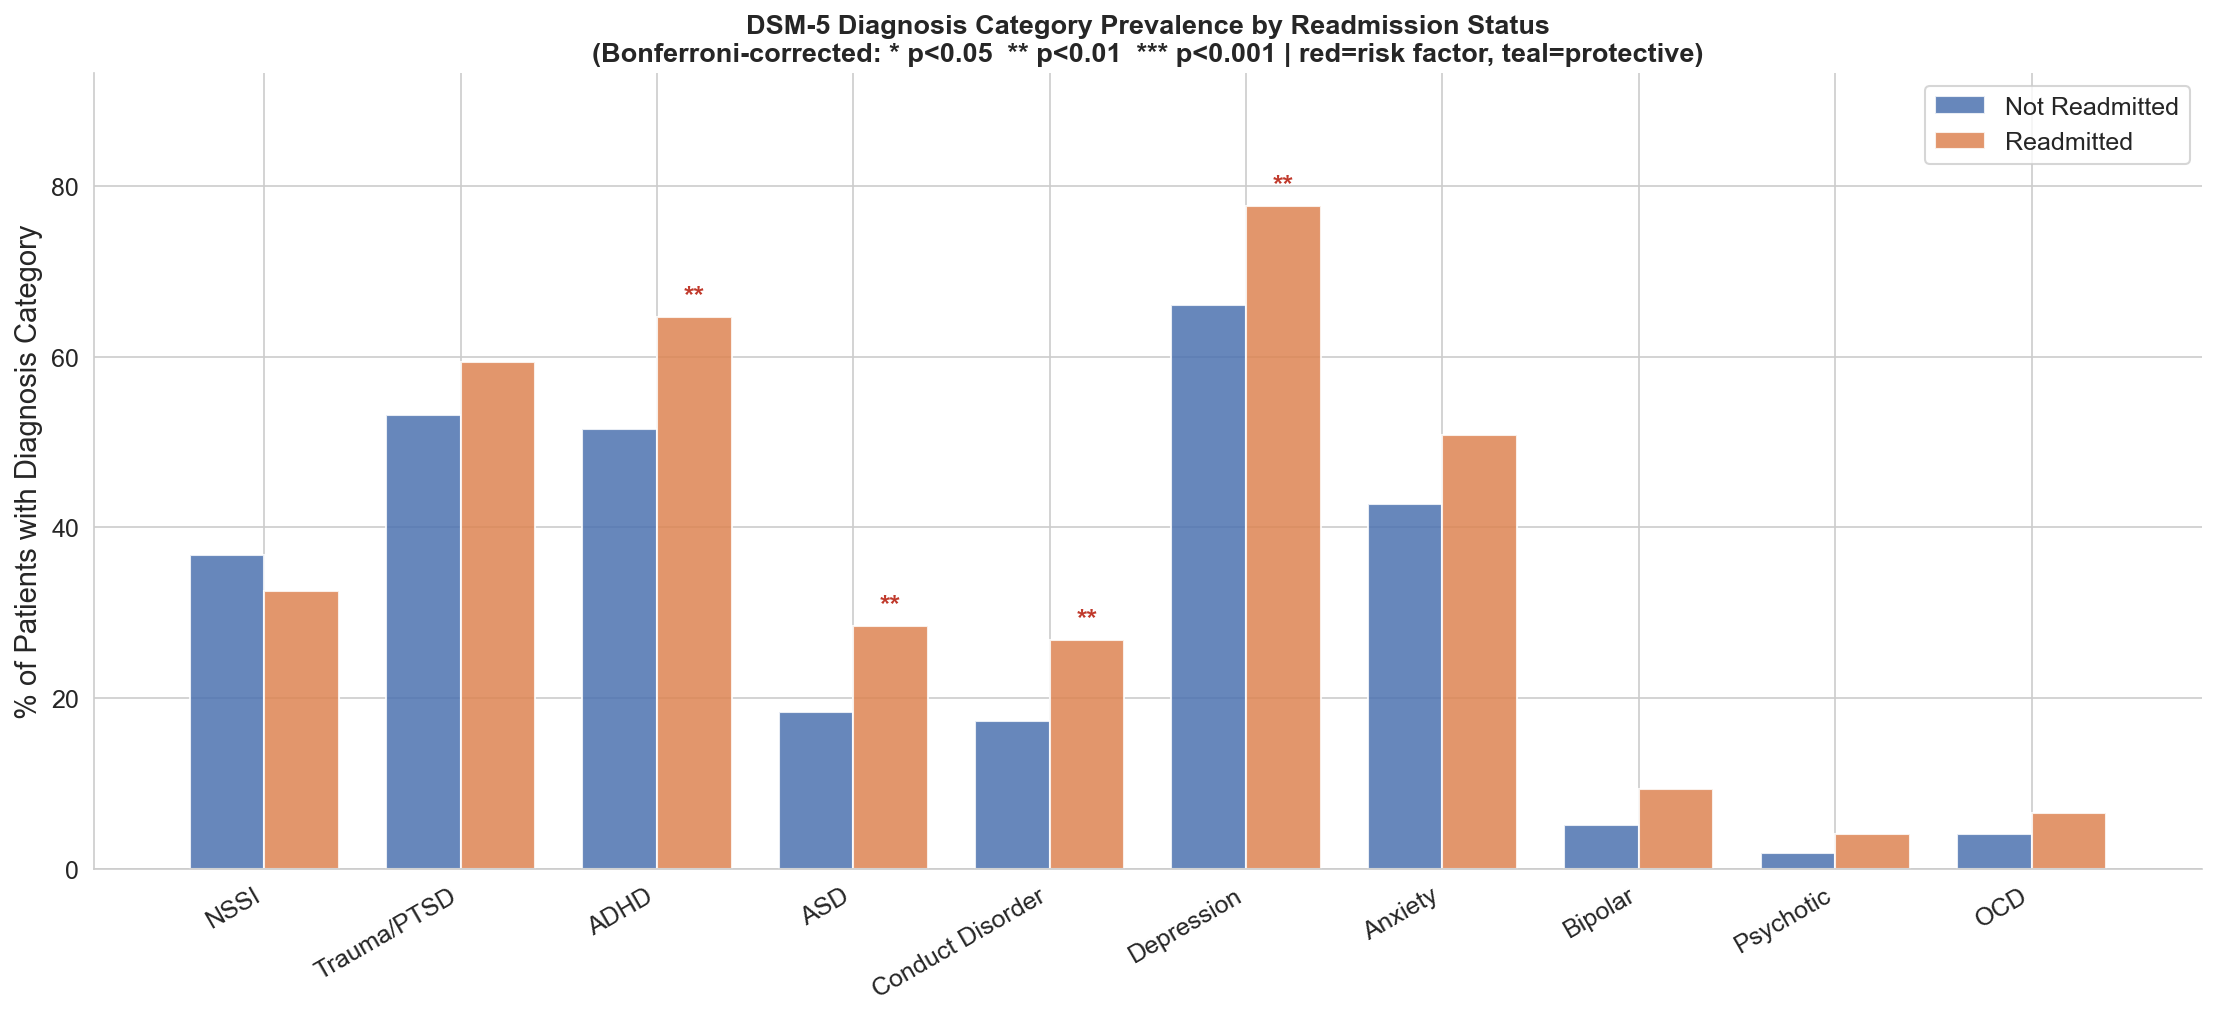

✓ Fig 6 saved

Significance summary (Bonferroni-corrected):
  ADHD                 **  (risk)
  ASD                  **  (risk)
  Conduct Disorder     **  (risk)
  Depression           **  (risk)


In [10]:

# ── Fig 6: DSM-5 diagnosis prevalence grouped bar + chi-squared significance ──
from scipy.stats import chi2_contingency

diag_flags = {
    'NSSI':             'has_nssi',
    'Trauma/PTSD':      'has_trauma',
    'ADHD':             'has_adhd',
    'ASD':              'has_asd',
    'Conduct Disorder': 'has_conduct',
    'Depression':       'has_depression',
    'Anxiety':          'has_anxiety',
    'Bipolar':          'has_bipolar',
    'Psychotic':        'has_psychotic',
    'OCD':              'has_ocd',
}
labels = list(diag_flags.keys())
cols   = list(diag_flags.values())

nra_pct = [nra[c].mean() * 100 for c in cols]
ra_pct  = [ra[c].mean() * 100  for c in cols]

# Chi-squared with Bonferroni correction
n_tests = len(cols)
sig_markers, directions = [], []
for c, nr, r in zip(cols, nra_pct, ra_pct):
    tab = pd.crosstab(df['readmitted'], df[c])
    _, p, _, _ = chi2_contingency(tab)
    p_bonf = min(p * n_tests, 1.0)
    star = '***' if p_bonf < 0.001 else ('**' if p_bonf < 0.01 else ('*' if p_bonf < 0.05 else ''))
    sig_markers.append(star)
    directions.append('risk' if r > nr else 'protective')

x = np.arange(len(labels))
width = 0.38

fig, ax = plt.subplots(figsize=(15, 7))
b1 = ax.bar(x - width/2, nra_pct, width, color=BLUE,   alpha=0.85, label='Not Readmitted', edgecolor='white')
b2 = ax.bar(x + width/2, ra_pct,  width, color=ORANGE, alpha=0.85, label='Readmitted',     edgecolor='white')

# Significance markers above the taller bar; teal for protective, red for risk
for i, (sig, direction) in enumerate(zip(sig_markers, directions)):
    if not sig:
        continue
    top  = max(nra_pct[i], ra_pct[i])
    xpos = x[i] + (width/2 if ra_pct[i] >= nra_pct[i] else -width/2)
    color = '#c0392b' if direction == 'risk' else '#16a085'
    ax.text(xpos, top + 1.5, sig, ha='center', fontsize=13, color=color, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=12)
ax.set_ylabel('% of Patients with Diagnosis Category')
ax.set_ylim(0, max(max(nra_pct), max(ra_pct)) * 1.2)
ax.set_title('DSM-5 Diagnosis Category Prevalence by Readmission Status\n'
             '(Bonferroni-corrected: * p<0.05  ** p<0.01  *** p<0.001 | red=risk factor, teal=protective)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/Fig6_diagnosis_prevalence.png')
plt.show()
print("✓ Fig 6 saved")
print("\nSignificance summary (Bonferroni-corrected):")
for lbl, sig, d in zip(labels, sig_markers, directions):
    if sig:
        print(f"  {lbl:<20} {sig}  ({d})")


In [11]:
# ── Logistic regression: build feature matrix ─────────────────────────────────

FEATURES = {
    # Demographics
    'age':                   'Age at admission (yrs)',
    'gender_male':           'Male gender identity (recorded at admission)',  # GenderCode = gender ID, NOT sex
    'insurance_public':      'Public insurance (AHCCCS)',
    # Clinical
    'ace_score':             'ACE score',
    'had_restraints':        'Physical restraint use',
    'csrss_any':             'Any C-SSRS flag (suicidality screen)',
    'los_days':              'Length of stay (days)',
    # Diagnostic complexity (distinct DSM-5 *categories*, not # of diagnoses)
    'n_dsm5_categories':     '# distinct DSM-5 categories',
    'has_medical_comorbidity': 'Medical comorbidity (ICD-prefix group flag; not a CCS category)',
    # Diagnosis flags = string match on DSM-5 *category* labels (NOT individual ICD codes, NOT PyHealth CCSR)
    'has_nssi':              'Non-suicidal self-injury (DSM-5 category)',
    'has_trauma':            'Trauma/stressor disorders (DSM-5 category)',
    'has_adhd':              'ADHD (DSM-5 category)',
    'has_asd':               'Autism spectrum (DSM-5 category)',
    'has_conduct':           'Conduct disorder (DSM-5 category)',
    'has_depression':        'Depressive disorders (DSM-5 category)',
    'has_anxiety':           'Anxiety disorders (DSM-5 category)',
    'has_bipolar':           'Bipolar disorders (DSM-5 category)',
    'has_psychotic':         'Psychotic disorders (DSM-5 category)',
    # Batch-2 additions (suicidality by ICD code; organic/neurocognitive flag)
    'has_suicidal_ideation': 'Suicidal ideation (ICD R45.851)',
    'has_neurocognitive':    'Neurocognitive/organic (ICD)',
}

feat_cols = list(FEATURES.keys())
model_df  = df[feat_cols + ['readmitted', 'csrss_red', 'csrss_orange', 'csrss_yellow', 'n_medical_chronic_pyhealth', 'has_ace_condition']].copy()

# MICE Imputation for missing ACE Score and LOS
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

imp_cols = ['age', 'ace_score', 'los_days']
imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=50, random_state=42), max_iter=10, random_state=42)

model_df[imp_cols] = imputer.fit_transform(model_df[imp_cols])

# Handle any remaining missing values
model_df = model_df.dropna()

print(f"Model dataset: {len(model_df):,} patients | {model_df['readmitted'].sum()} readmitted ({model_df['readmitted'].mean():.1%})")
print(f"Features: {len(feat_cols)}")

Model dataset: 2,652 patients | 246 readmitted (9.3%)
Features: 20


Overall Readmission Stats (Continuous):
  Mean # Readmissions: 0.10 ± 0.34
  Readmitted (%):      9.3%

ACE Score Stats:
  Mean:   3.7 ± 2.6
  Median: 3.0
  N collected: 1569 (59.2%)

Length of Stay (LOS):
  Mean:   10.0 ± 6.9
  Median: 8.0

Diagnostic Burdens (Mean ± SD, Median):
  Visit                4.3 ± 2.3 | Mdn: 4.0
  Chronic              5.3 ± 5.4 | Mdn: 4.0
  Non-Suicidal (NSSI)  0.4 ± 0.5 | Mdn: 0.0

Medical Comorbidity Breakdown (Top Types; categories may overlap by patient):
               type   n Patient % Mention %
       GI/Digestive 240      9.0%     27.5%
  Metabolic/Obesity 217      8.2%     24.8%
     Sleep Disorder 180      6.8%     20.6%
Respiratory/Allergy 135      5.1%     15.4%
     Renal/Urologic 102      3.8%     11.7%


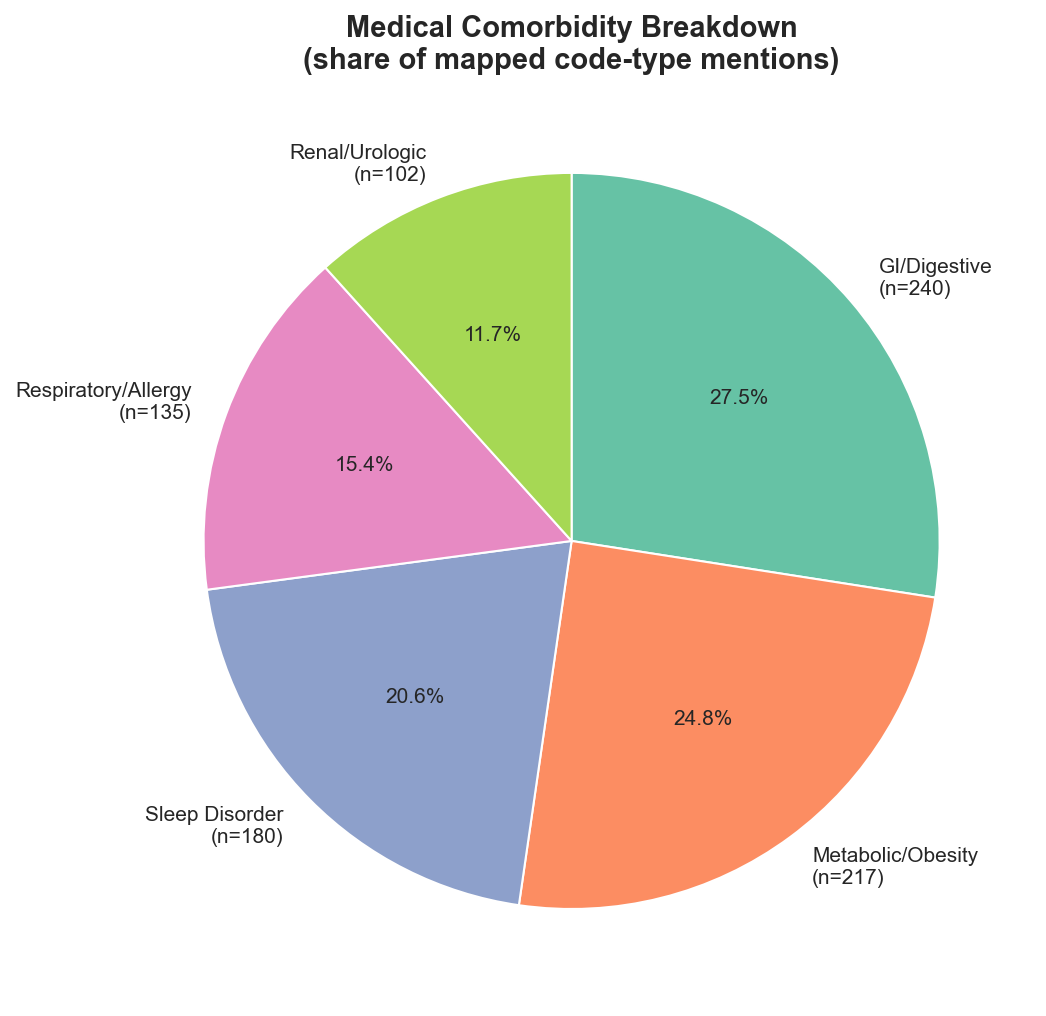


✓ Medical comorbidity breakdown saved


In [12]:

# ── Cohort Summary & Detailed Descriptive Statistics ──────────────────────────
# Continuous Readmissions
print(f"Overall Readmission Stats (Continuous):")
print(f"  Mean # Readmissions: {df['Readmissions'].mean():.2f} ± {df['Readmissions'].std():.2f}")
print(f"  Readmitted (%):      {df['readmitted'].mean():.1%}")

# ACE Score Detailed
ace_sub = df['ace_score'].dropna()
print(f"\nACE Score Stats:")
print(f"  Mean:   {ace_sub.mean():.1f} ± {ace_sub.std():.1f}")
print(f"  Median: {ace_sub.median():.1f}")
print(f"  N collected: {len(ace_sub)} ({len(ace_sub)/len(df):.1%})")

# LOS Detailed
print(f"\nLength of Stay (LOS):")
print(f"  Mean:   {df['los_days'].mean():.1f} ± {df['los_days'].std():.1f}")
print(f"  Median: {df['los_days'].median():.1f}")

# Diagnostic Counts
print(f"\nDiagnostic Burdens (Mean ± SD, Median):")
for col, label in [('n_visit_diags', 'Visit'), ('n_chronic_diags', 'Chronic'), ('has_nssi', 'Non-Suicidal (NSSI)')]:
    print(f"  {label:<20} {df[col].mean():.1f} ± {df[col].std():.1f} | Mdn: {df[col].median():.1f}")

# Medical Comorbidity Breakdown
all_m = [t for sublist in df['medical_comorbidity_types'] for t in sublist]
med_counts = pd.Series(all_m, name='Medical comorbidity type').value_counts()
med_breakdown = (
    med_counts.rename_axis('type')
    .reset_index(name='n')
    .assign(
        pct_of_patients=lambda x: 100 * x['n'] / len(df),
        pct_of_mentions=lambda x: 100 * x['n'] / x['n'].sum(),
    )
)
med_breakdown.to_csv('figures/Medical_Comorbidity_Breakdown.csv', index=False)

print(f"\nMedical Comorbidity Breakdown (Top Types; categories may overlap by patient):")
if med_breakdown.empty:
    print("  No mapped medical comorbidity categories found.")
else:
    display_breakdown = med_breakdown.copy()
    display_breakdown['Patient %'] = display_breakdown['pct_of_patients'].map(lambda x: f'{x:.1f}%')
    display_breakdown['Mention %'] = display_breakdown['pct_of_mentions'].map(lambda x: f'{x:.1f}%')
    print(display_breakdown[['type', 'n', 'Patient %', 'Mention %']].to_string(index=False))

    fig, ax = plt.subplots(figsize=(8, 7))
    labels = [f"{row.type}\n(n={int(row.n)})" for row in med_breakdown.itertuples()]
    colors_med = sns.color_palette('Set2', n_colors=len(med_breakdown))
    ax.pie(
        med_breakdown['n'],
        labels=labels,
        autopct='%1.1f%%',
        startangle=90,
        counterclock=False,
        colors=colors_med,
        textprops={'fontsize': 10},
        wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    )
    ax.set_title('Medical Comorbidity Breakdown\n(share of mapped code-type mentions)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('figures/Fig_medical_comorbidity_breakdown.png')
    plt.show()
    print("\n✓ Medical comorbidity breakdown saved")

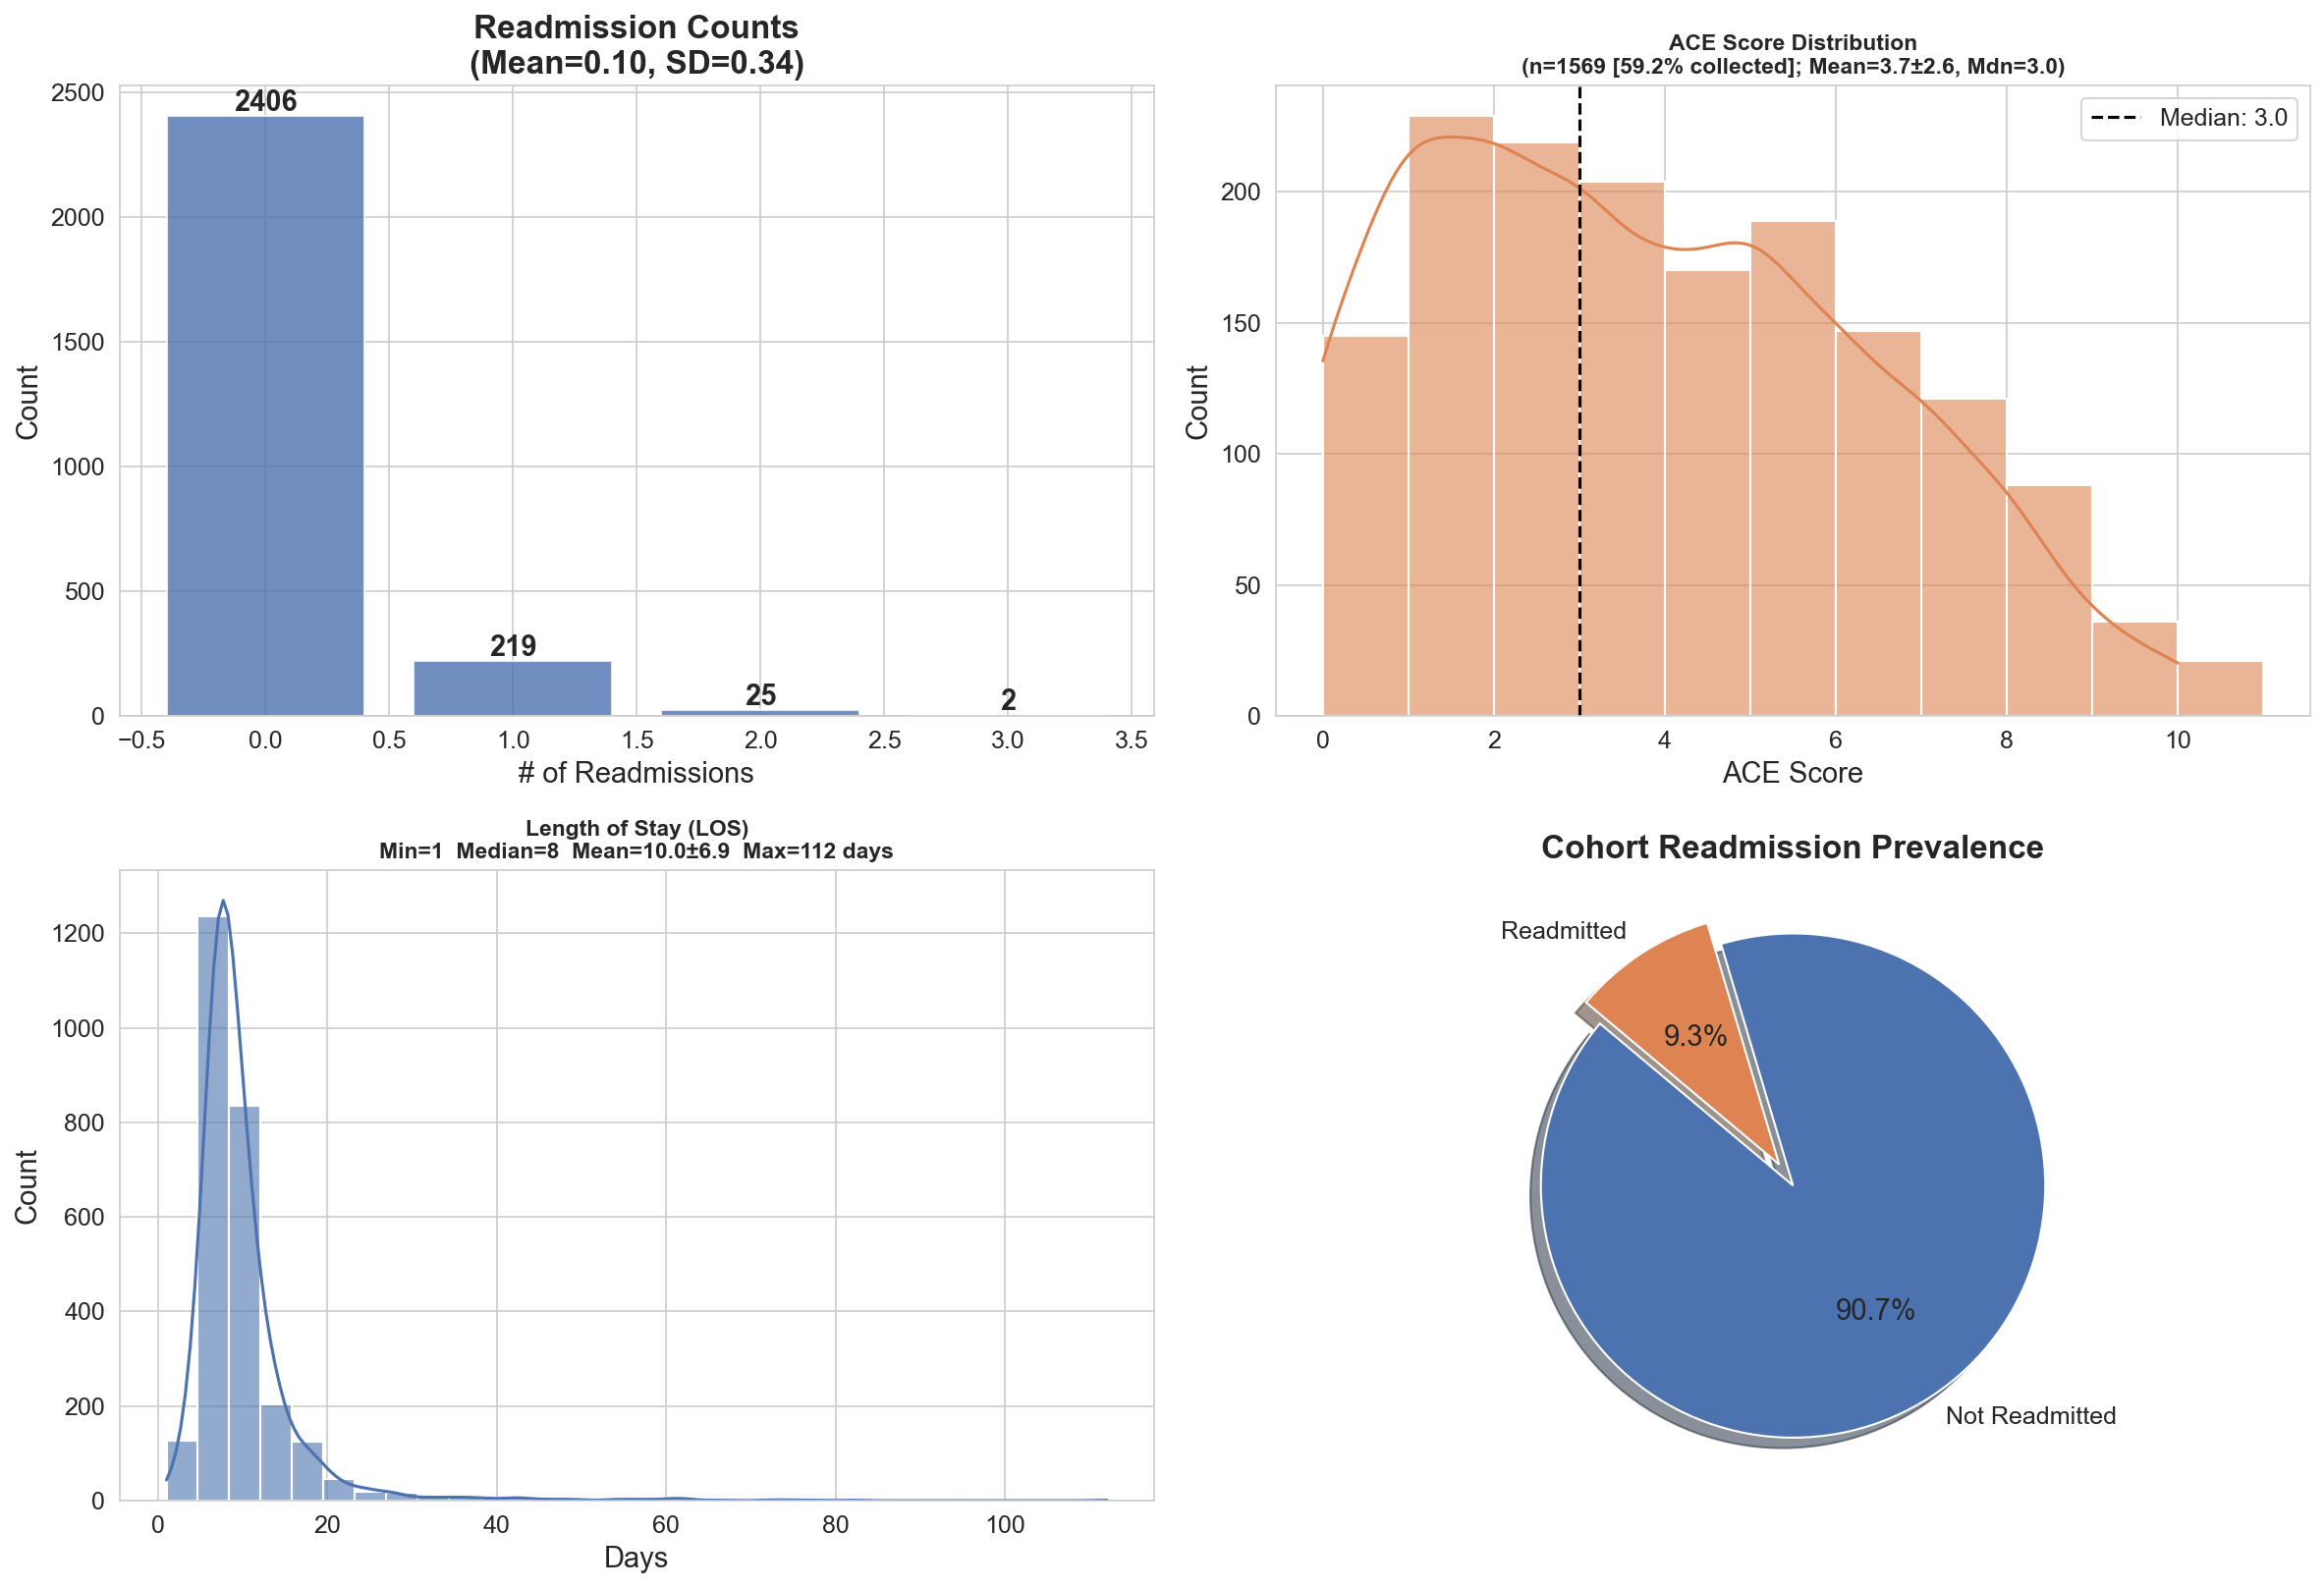

✓ Cohort visualizations saved


In [13]:

# ── Cohort Descriptive Visualizations ─────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Readmission Count Distribution
rc_counts = df['Readmissions'].fillna(0).value_counts().sort_index()
rc_mean = df['Readmissions'].fillna(0).mean()
rc_sd   = df['Readmissions'].fillna(0).std()
axes[0, 0].bar(rc_counts.index.astype(int), rc_counts.values, color=BLUE, alpha=0.8, edgecolor='white')
axes[0, 0].set_title(f"Readmission Counts\n(Mean={rc_mean:.2f}, SD={rc_sd:.2f})", fontweight='bold')
axes[0, 0].set_xlabel("# of Readmissions")
axes[0, 0].set_ylabel("Count")
for i, v in enumerate(rc_counts.values):
    axes[0, 0].text(rc_counts.index[i], v + 20, str(v), ha='center', fontweight='bold')

# 2. ACE Score Distribution
ace_sub = df['ace_score'].dropna()
sns.histplot(ace_sub, bins=range(0, 12), ax=axes[0, 1], color=ORANGE, kde=True, alpha=0.6)
axes[0, 1].set_title(
    f"ACE Score Distribution\n"
    f"(n={len(ace_sub)} [{100*len(ace_sub)/len(df):.1f}% collected]; "
    f"Mean={ace_sub.mean():.1f}±{ace_sub.std():.1f}, Mdn={ace_sub.median():.1f})",
    fontweight='bold', fontsize=11)
axes[0, 1].set_xlabel("ACE Score")
axes[0, 1].axvline(ace_sub.median(), color='black', linestyle='--', label=f'Median: {ace_sub.median():.1f}')
axes[0, 1].legend()

# 3. Length of Stay (LOS) Distribution  — with min, median, mean±SD, max
los = df['los_days'].dropna()
sns.histplot(los, bins=30, ax=axes[1, 0], color=BLUE, kde=True, alpha=0.6)
axes[1, 0].set_title(
    f"Length of Stay (LOS)\n"
    f"Min={los.min():.0f}  Median={los.median():.0f}  "
    f"Mean={los.mean():.1f}±{los.std():.1f}  Max={los.max():.0f} days",
    fontweight='bold', fontsize=11)
axes[1, 0].set_xlabel("Days")

# 4. Cohort Readmission Prevalence
ra_pct = df['readmitted'].mean() * 100
axes[1, 1].pie([100-ra_pct, ra_pct], labels=['Not Readmitted', 'Readmitted'],
               autopct='%1.1f%%', colors=[BLUE, ORANGE], startangle=140,
               explode=(0, 0.1), shadow=True)
axes[1, 1].set_title("Cohort Readmission Prevalence", fontweight='bold')

plt.tight_layout()
plt.savefig('figures/Cohort_Descriptive_Overview.png')
plt.show()
print("✓ Cohort visualizations saved")


In [14]:
# ── Logistic regression model + interaction terms ─────────────────────────────
# We test specific interactions hypothesized to be clinically relevant

# Keep a copy of unscaled for tree models
model_df_unscaled = model_df.copy()

# Standardize continuous variables for Odds Ratio interpretation and visible CIs
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scale_cols = ['age', 'los_days', 'ace_score', 'n_dsm5_categories']
model_df[scale_cols] = scaler.fit_transform(model_df[scale_cols])

interaction_labels = {
    'complexity_x_age': 'Age × Diagnostic Complexity',
    'ace_x_csrss':      'ACE Score × Any C-SSRS Flag',
    'medical_x_los':    'Medical Comorbidity × LOS',
}

model_df['complexity_x_age'] = model_df['n_dsm5_categories'] * model_df['age']
model_df['ace_x_csrss']      = model_df['ace_score'] * model_df['csrss_any']
model_df['medical_x_los']    = model_df['has_medical_comorbidity'] * model_df['los_days']
model_df_unscaled['complexity_x_age'] = model_df_unscaled['n_dsm5_categories'] * model_df_unscaled['age']
model_df_unscaled['ace_x_csrss']      = model_df_unscaled['ace_score'] * model_df_unscaled['csrss_any']
model_df_unscaled['medical_x_los']    = model_df_unscaled['has_medical_comorbidity'] * model_df_unscaled['los_days']

all_x_cols = feat_cols + list(interaction_labels.keys())

# Scale interactions
scaler_interactions = StandardScaler()
model_df[list(interaction_labels.keys())] = scaler_interactions.fit_transform(model_df[list(interaction_labels.keys())])


X = model_df[all_x_cols]
X = sm.add_constant(X)
y = model_df['readmitted']

logit_model = sm.Logit(y, X).fit(maxiter=200)
print(logit_model.summary2())

Optimization terminated successfully.
         Current function value: 0.282811
         Iterations 7
                            Results: Logit
Model:                Logit              Method:             MLE       
Dependent Variable:   readmitted         Pseudo R-squared:   0.084     
Date:                 2026-06-04 13:42   AIC:                1548.0318 
No. Observations:     2652               BIC:                1689.2255 
Df Model:             23                 Log-Likelihood:     -750.02   
Df Residuals:         2628               LL-Null:            -819.14   
Converged:            1.0000             LLR p-value:        1.9463e-18
No. Iterations:       7.0000             Scale:              1.0000    
-----------------------------------------------------------------------
                         Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
-----------------------------------------------------------------------
const                   -3.5280   0.3883 -9.0853 0.0000 -4.2891

                    feature          pval        OR
1                       age  1.481676e-02  0.819775
2               gender_male  9.850869e-01  0.997078
3          insurance_public  5.094420e-01  1.105996
4                 ace_score  7.720858e-01  1.029639
5            had_restraints  2.099568e-02  1.526542
6                 csrss_any  9.691714e-01  0.994005
7                  los_days  8.954141e-01  0.986690
8         n_dsm5_categories  8.651408e-03  1.388332
9   has_medical_comorbidity  6.013431e-01  0.926640
10                 has_nssi  3.125691e-05  0.419201
11               has_trauma  3.627884e-01  1.171163
12                 has_adhd  8.187921e-01  1.045673
13                  has_asd  2.827532e-01  1.242764
14              has_conduct  7.209536e-02  1.405604
15           has_depression  1.228017e-03  1.859152
16              has_anxiety  2.543606e-01  1.222380
17              has_bipolar  2.761177e-01  1.346679
18            has_psychotic  3.084309e-01  1.502276
19    has_su

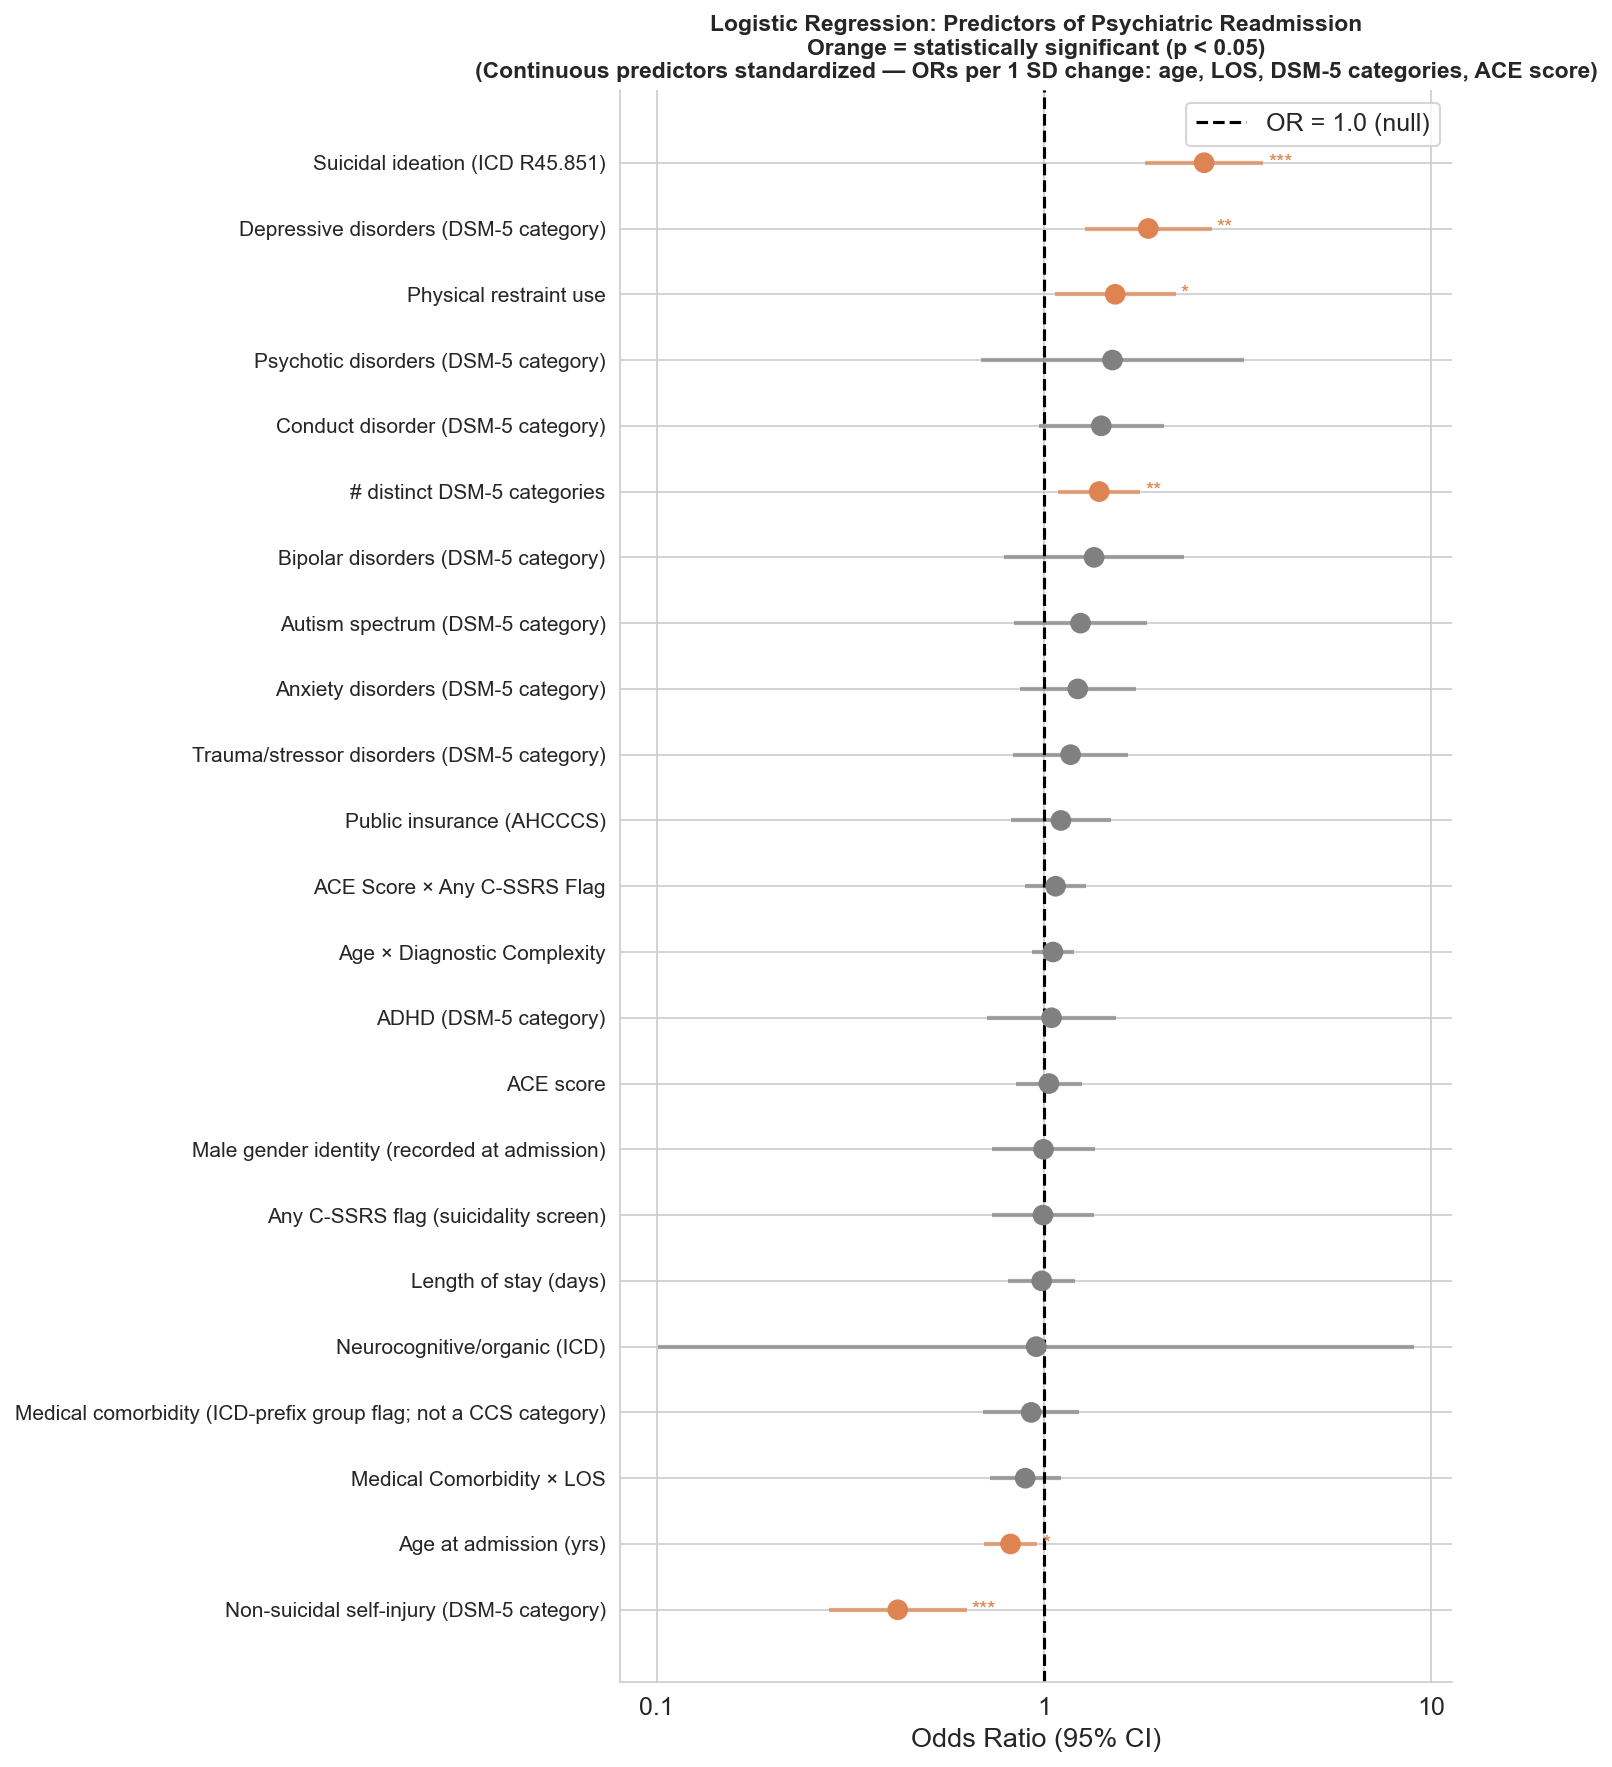

✓ Fig 7 saved


In [15]:

# ── Fig 7: Forest plot — odds ratios from logistic regression ─────────────────
all_labels = {**FEATURES, **interaction_labels}

coef_df = pd.DataFrame({
    'feature': logit_model.params.index,
    'coef':    logit_model.params.values,
    'se':      logit_model.bse.values,
    'pval':    logit_model.pvalues.values,
}).query("feature != 'const'")

coef_df['OR']    = np.exp(coef_df['coef'])
print (coef_df[['feature', 'pval', 'OR']])
coef_df['OR_lo'] = np.exp(coef_df['coef'] - 1.96 * coef_df['se'])
coef_df['OR_hi'] = np.exp(coef_df['coef'] + 1.96 * coef_df['se'])
coef_df['label'] = coef_df['feature'].map(all_labels).fillna(coef_df['feature'])
coef_df['sig']   = coef_df['pval'] < 0.05
coef_df = coef_df.sort_values('OR', ascending=True)

fig, ax = plt.subplots(figsize=(10, 12))
y_pos = range(len(coef_df))
colors_lr = [ORANGE if s else 'gray' for s in coef_df['sig']]

ax.scatter(coef_df['OR'], y_pos, color=colors_lr, s=80, zorder=3)
ax.hlines(y_pos, coef_df['OR_lo'], coef_df['OR_hi'], 
          color=colors_lr, linewidth=2, alpha=0.7)
ax.axvline(1.0, color='black', linestyle='--', linewidth=1.5, label='OR = 1.0 (null)')
ax.set_yticks(y_pos)
ax.set_yticklabels(coef_df['label'], fontsize=10)
ax.set_xlabel('Odds Ratio (95% CI)', fontsize=13)
ax.set_title('Logistic Regression: Predictors of Psychiatric Readmission\n'
             'Orange = statistically significant (p < 0.05)\n'
             '(Continuous predictors standardized — ORs per 1 SD change: age, LOS, DSM-5 categories, ACE score)',
             fontsize=11, fontweight='bold')
ax.set_xscale('log')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.2g}'))

# Annotate p-values for significant predictors
for i, (_, row) in enumerate(coef_df.iterrows()):
    if row['sig']:
        p_str = '***' if row['pval'] < 0.001 else ('**' if row['pval'] < 0.01 else '*')
        ax.text(row['OR_hi'] * 1.03, i, p_str, va='center', fontsize=10, color=ORANGE)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend()
plt.tight_layout()
plt.savefig('figures/Fig7_forest_plot.png')
plt.show()
print("✓ Fig 7 saved")


## Batch-2 cohort descriptives — ACE tiers, trends over time, ICD-group & insurance breakdowns
Added descriptive views on the complete cohort (uses the augmented features from the preamble).

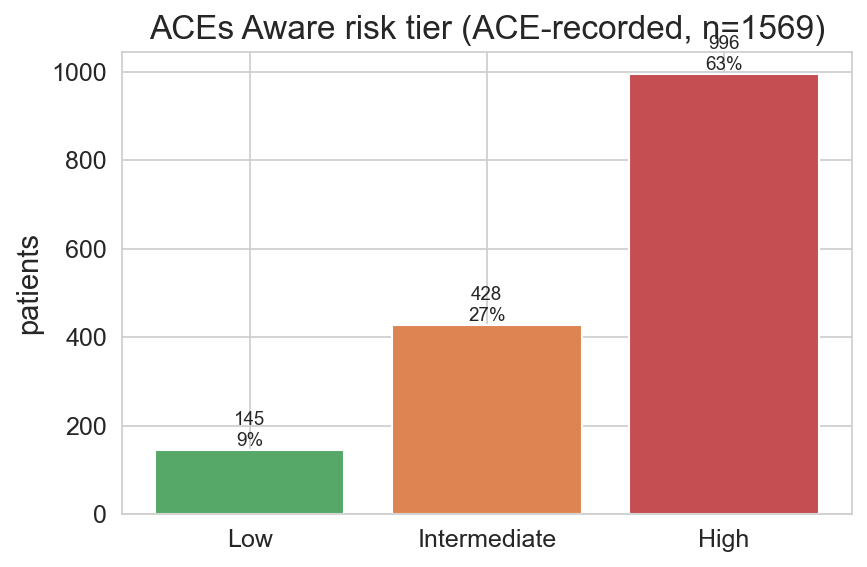

ACE tiers: {'Low': np.int64(145), 'Intermediate': np.int64(428), 'High': np.int64(996)} | readmit% by tier: {'Low': np.float64(5.5), 'Intermediate': np.float64(8.9), 'High': np.float64(9.4)}


In [16]:
# ACE risk tiers (ACEs Aware pediatric) — single panel; histogram removed (appears in cohort overview)
fig, ax = plt.subplots(figsize=(6, 4))
av = df[df['ace_score'].notna()]; order = ['Low', 'Intermediate', 'High']
tc = av['ace_risk_tier'].value_counts().reindex(order).fillna(0).astype(int)
ax.bar(order, tc.values, color=['#55A868', '#DD8452', '#C44E52'])
ax.set_title('ACEs Aware risk tier (ACE-recorded, n=%d)' % len(av))
ax.set_ylabel('patients')
for i, v in enumerate(tc.values):
    ax.text(i, v, f'{v}\n{v/len(av)*100:.0f}%', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('figures/P1_ace_tiers.png', dpi=150)
plt.show()
print('ACE tiers:', dict(tc), '| readmit% by tier:',
      {t: round(av[av.ace_risk_tier==t]['readmitted'].mean()*100, 1) for t in order})


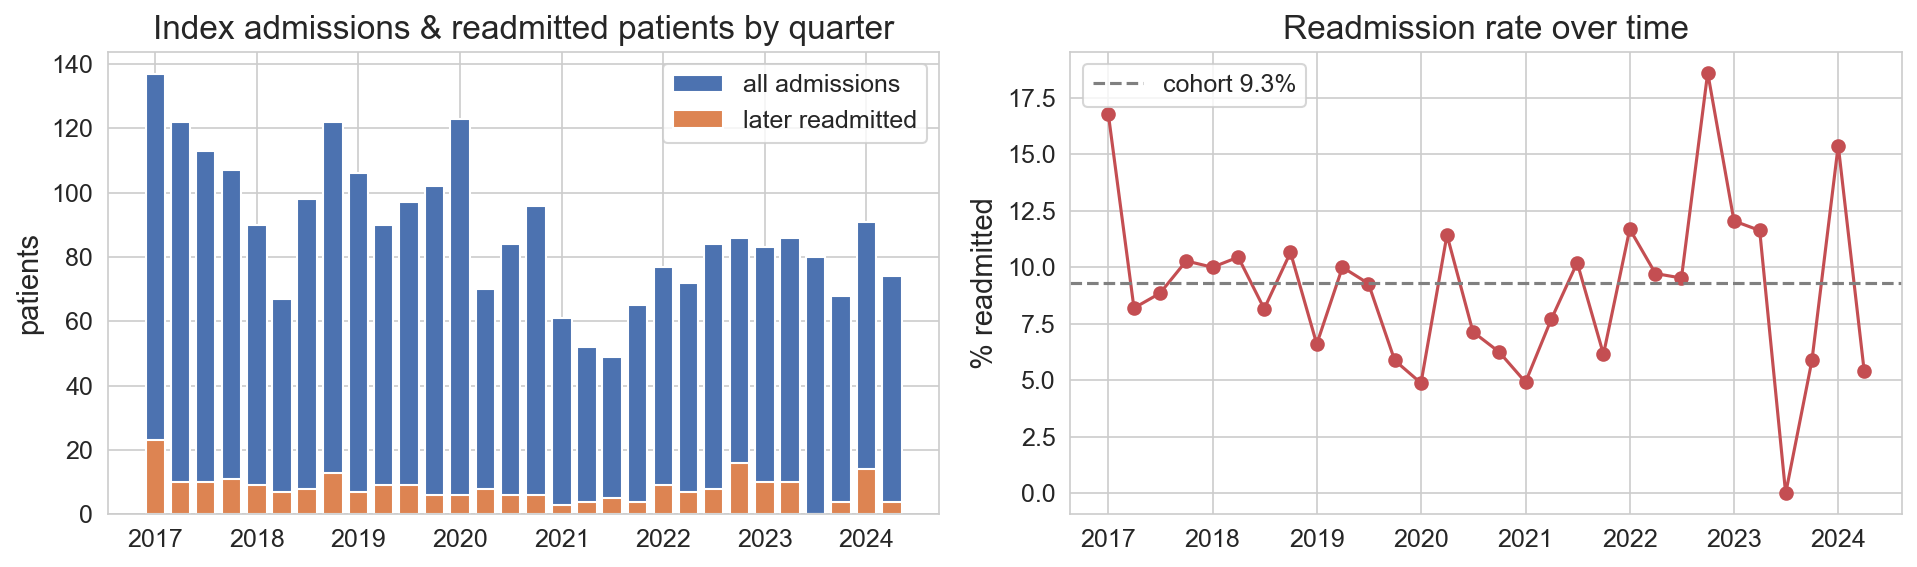

admissions by year: {2017: np.int64(479), 2018: np.int64(377), 2019: np.int64(395), 2020: np.int64(373), 2021: np.int64(227), 2022: np.int64(319), 2023: np.int64(317), 2024: np.int64(165)}


In [17]:
# Admissions & readmitted patients over time (index-admission date; quarterly)
d=df.copy(); d['ym']=pd.to_datetime(d['VisitDate'],errors='coerce').dt.to_period('Q').dt.to_timestamp()
g=d.dropna(subset=['ym']).groupby('ym').agg(admissions=('readmitted','size'),readmitted=('readmitted','sum'))
g['rate']=g['readmitted']/g['admissions']*100
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].bar(g.index,g['admissions'],width=70,color='#4C72B0',label='all admissions'); ax[0].bar(g.index,g['readmitted'],width=70,color='#DD8452',label='later readmitted')
ax[0].set_title('Index admissions & readmitted patients by quarter'); ax[0].set_ylabel('patients'); ax[0].legend()
ax[1].plot(g.index,g['rate'],marker='o',color='#C44E52'); ax[1].axhline(9.3,color='gray',ls='--',label='cohort 9.3%'); ax[1].set_title('Readmission rate over time'); ax[1].set_ylabel('% readmitted'); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/P1_over_time.png',dpi=150); plt.show()
print('admissions by year:',dict(pd.to_datetime(df['VisitDate'],errors='coerce').dt.year.value_counts().sort_index()))

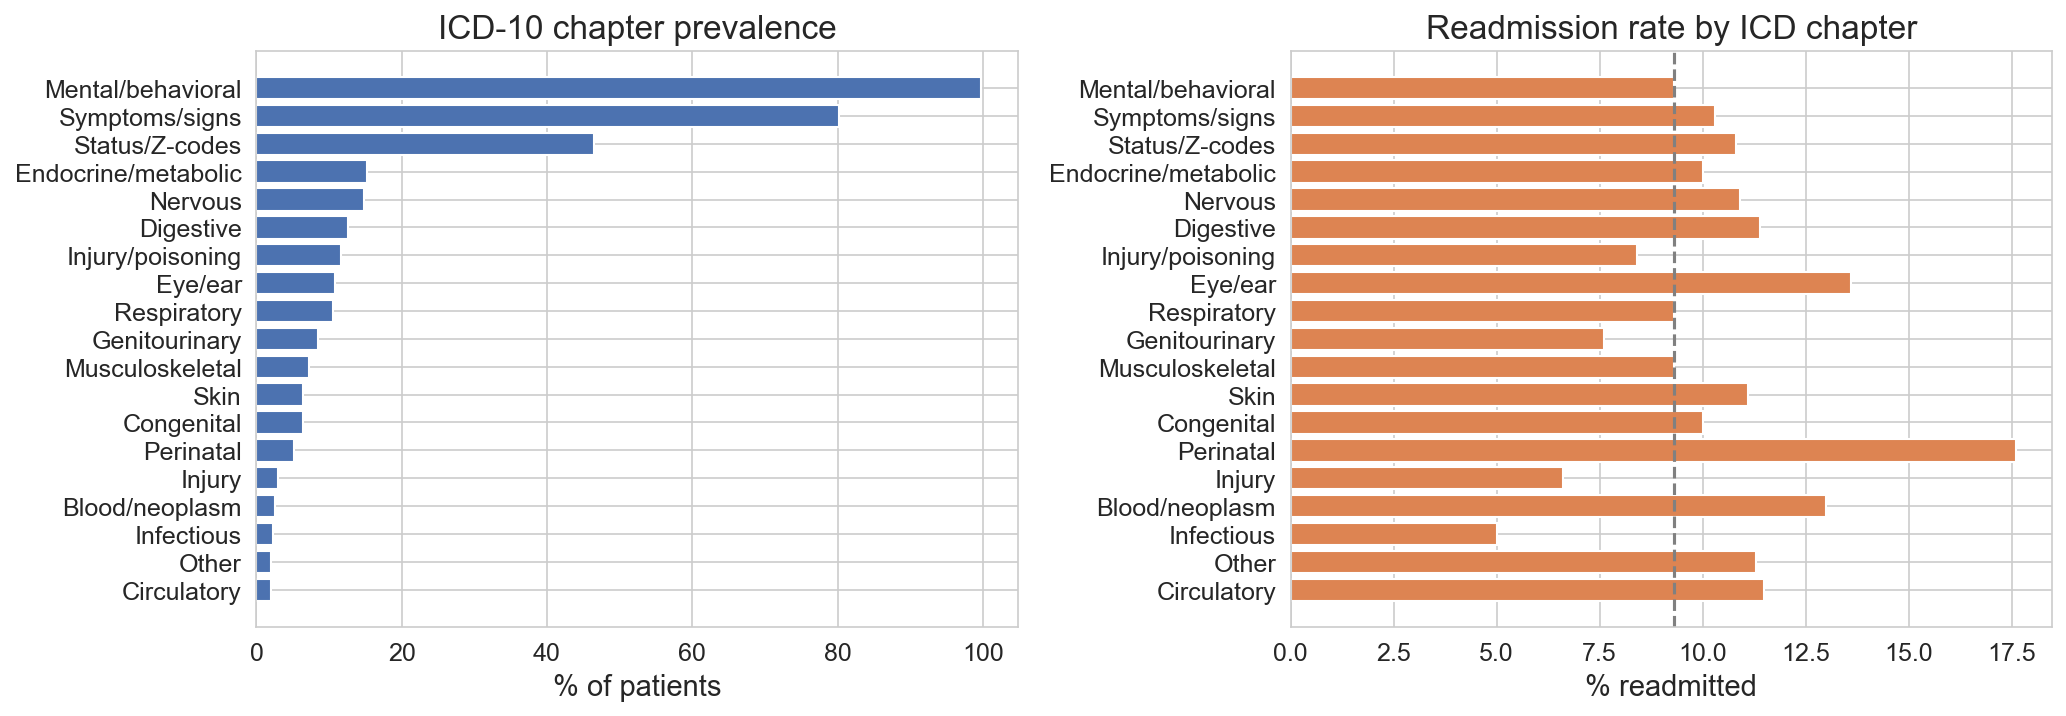

            chapter    n  pct  readmit_pct
  Mental/behavioral 2648 99.8          9.3
     Symptoms/signs 2127 80.2         10.3
     Status/Z-codes 1232 46.5         10.8
Endocrine/metabolic  402 15.2         10.0
            Nervous  393 14.8         10.9
          Digestive  334 12.6         11.4
   Injury/poisoning  308 11.6          8.4
            Eye/ear  287 10.8         13.6
        Respiratory  280 10.6          9.3
      Genitourinary  225  8.5          7.6
    Musculoskeletal  194  7.3          9.3
               Skin  171  6.4         11.1
         Congenital  170  6.4         10.0
          Perinatal  136  5.1         17.6
             Injury   76  2.9          6.6
     Blood/neoplasm   69  2.6         13.0
         Infectious   60  2.3          5.0
              Other   53  2.0         11.3
        Circulatory   52  2.0         11.5


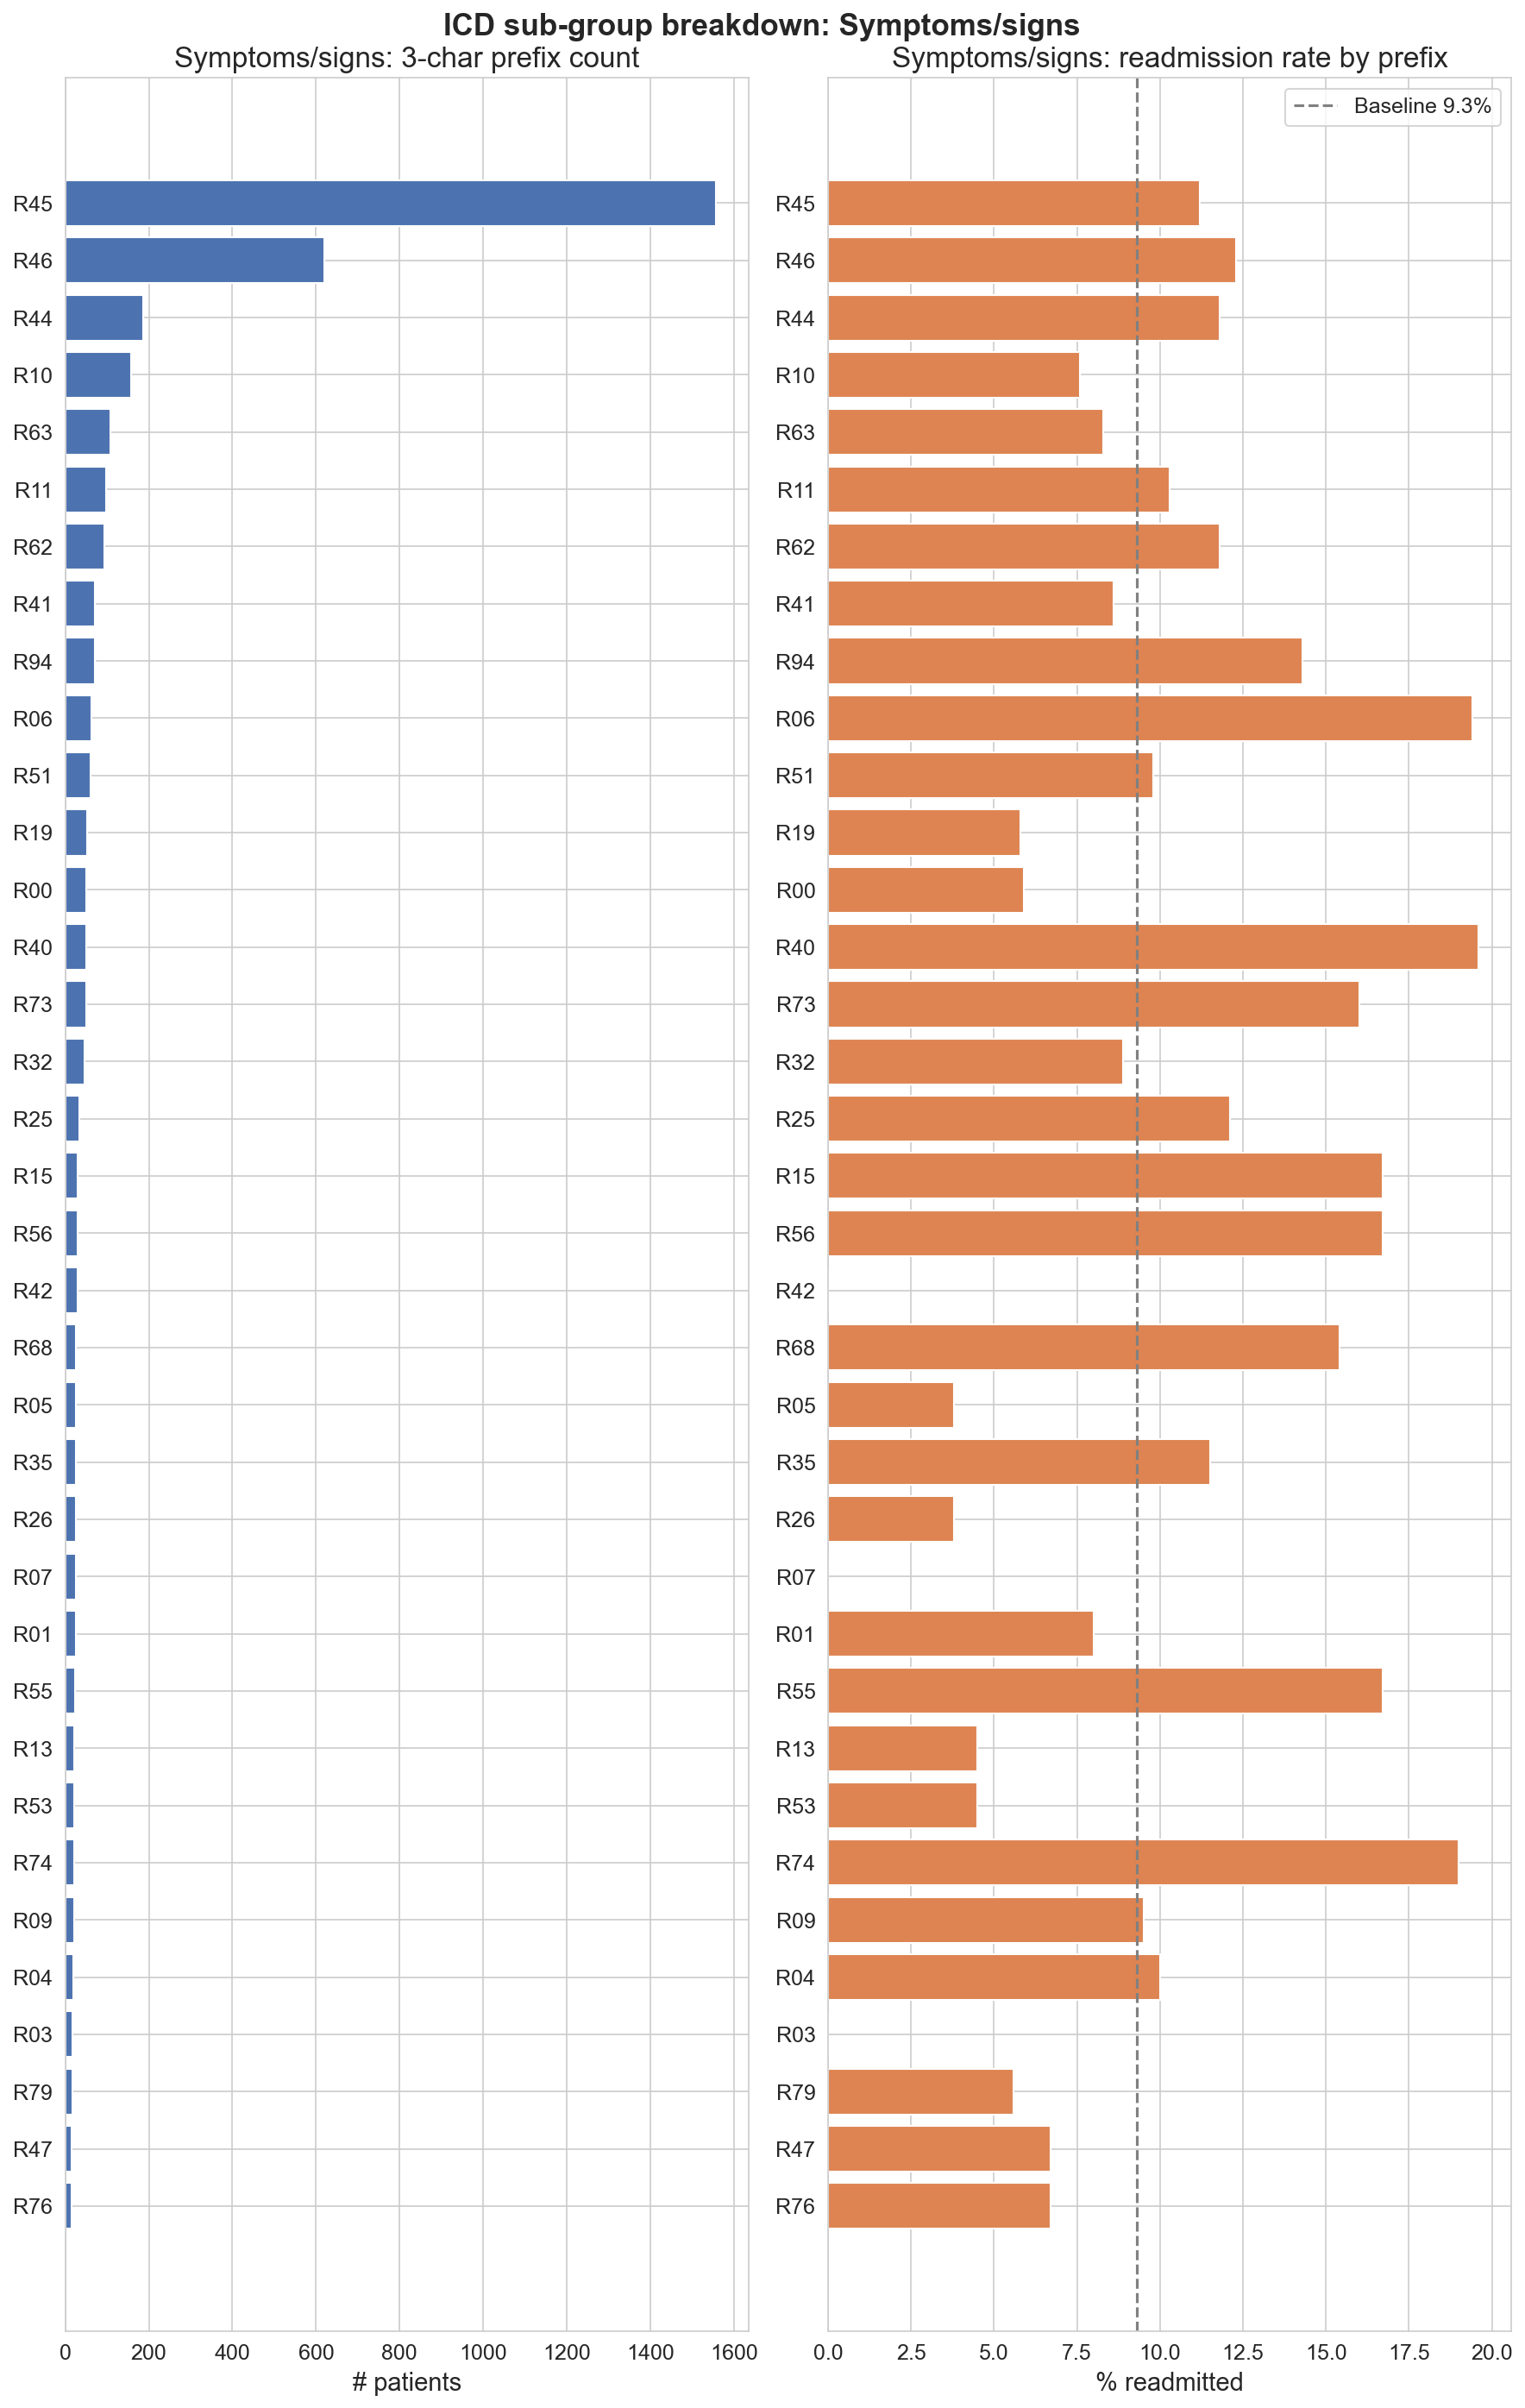

prefix    n  readmit_pct
   R45 1557         11.2
   R46  620         12.3
   R44  186         11.8
   R10  157          7.6
   R63  108          8.3
   R11   97         10.3
   R62   93         11.8
   R41   70          8.6
   R94   70         14.3
   R06   62         19.4
   R51   61          9.8
   R19   52          5.8
   R00   51          5.9
   R40   51         19.6
   R73   50         16.0
   R32   45          8.9
   R25   33         12.1
   R15   30         16.7
   R56   30         16.7
   R42   29          0.0
   R68   26         15.4
   R05   26          3.8
   R35   26         11.5
   R26   26          3.8
   R07   25          0.0
   R01   25          8.0
   R55   24         16.7
   R13   22          4.5
   R53   22          4.5
   R74   21         19.0
   R09   21          9.5
   R04   20         10.0
   R03   18          0.0
   R79   18          5.6
   R47   15          6.7
   R76   15          6.7


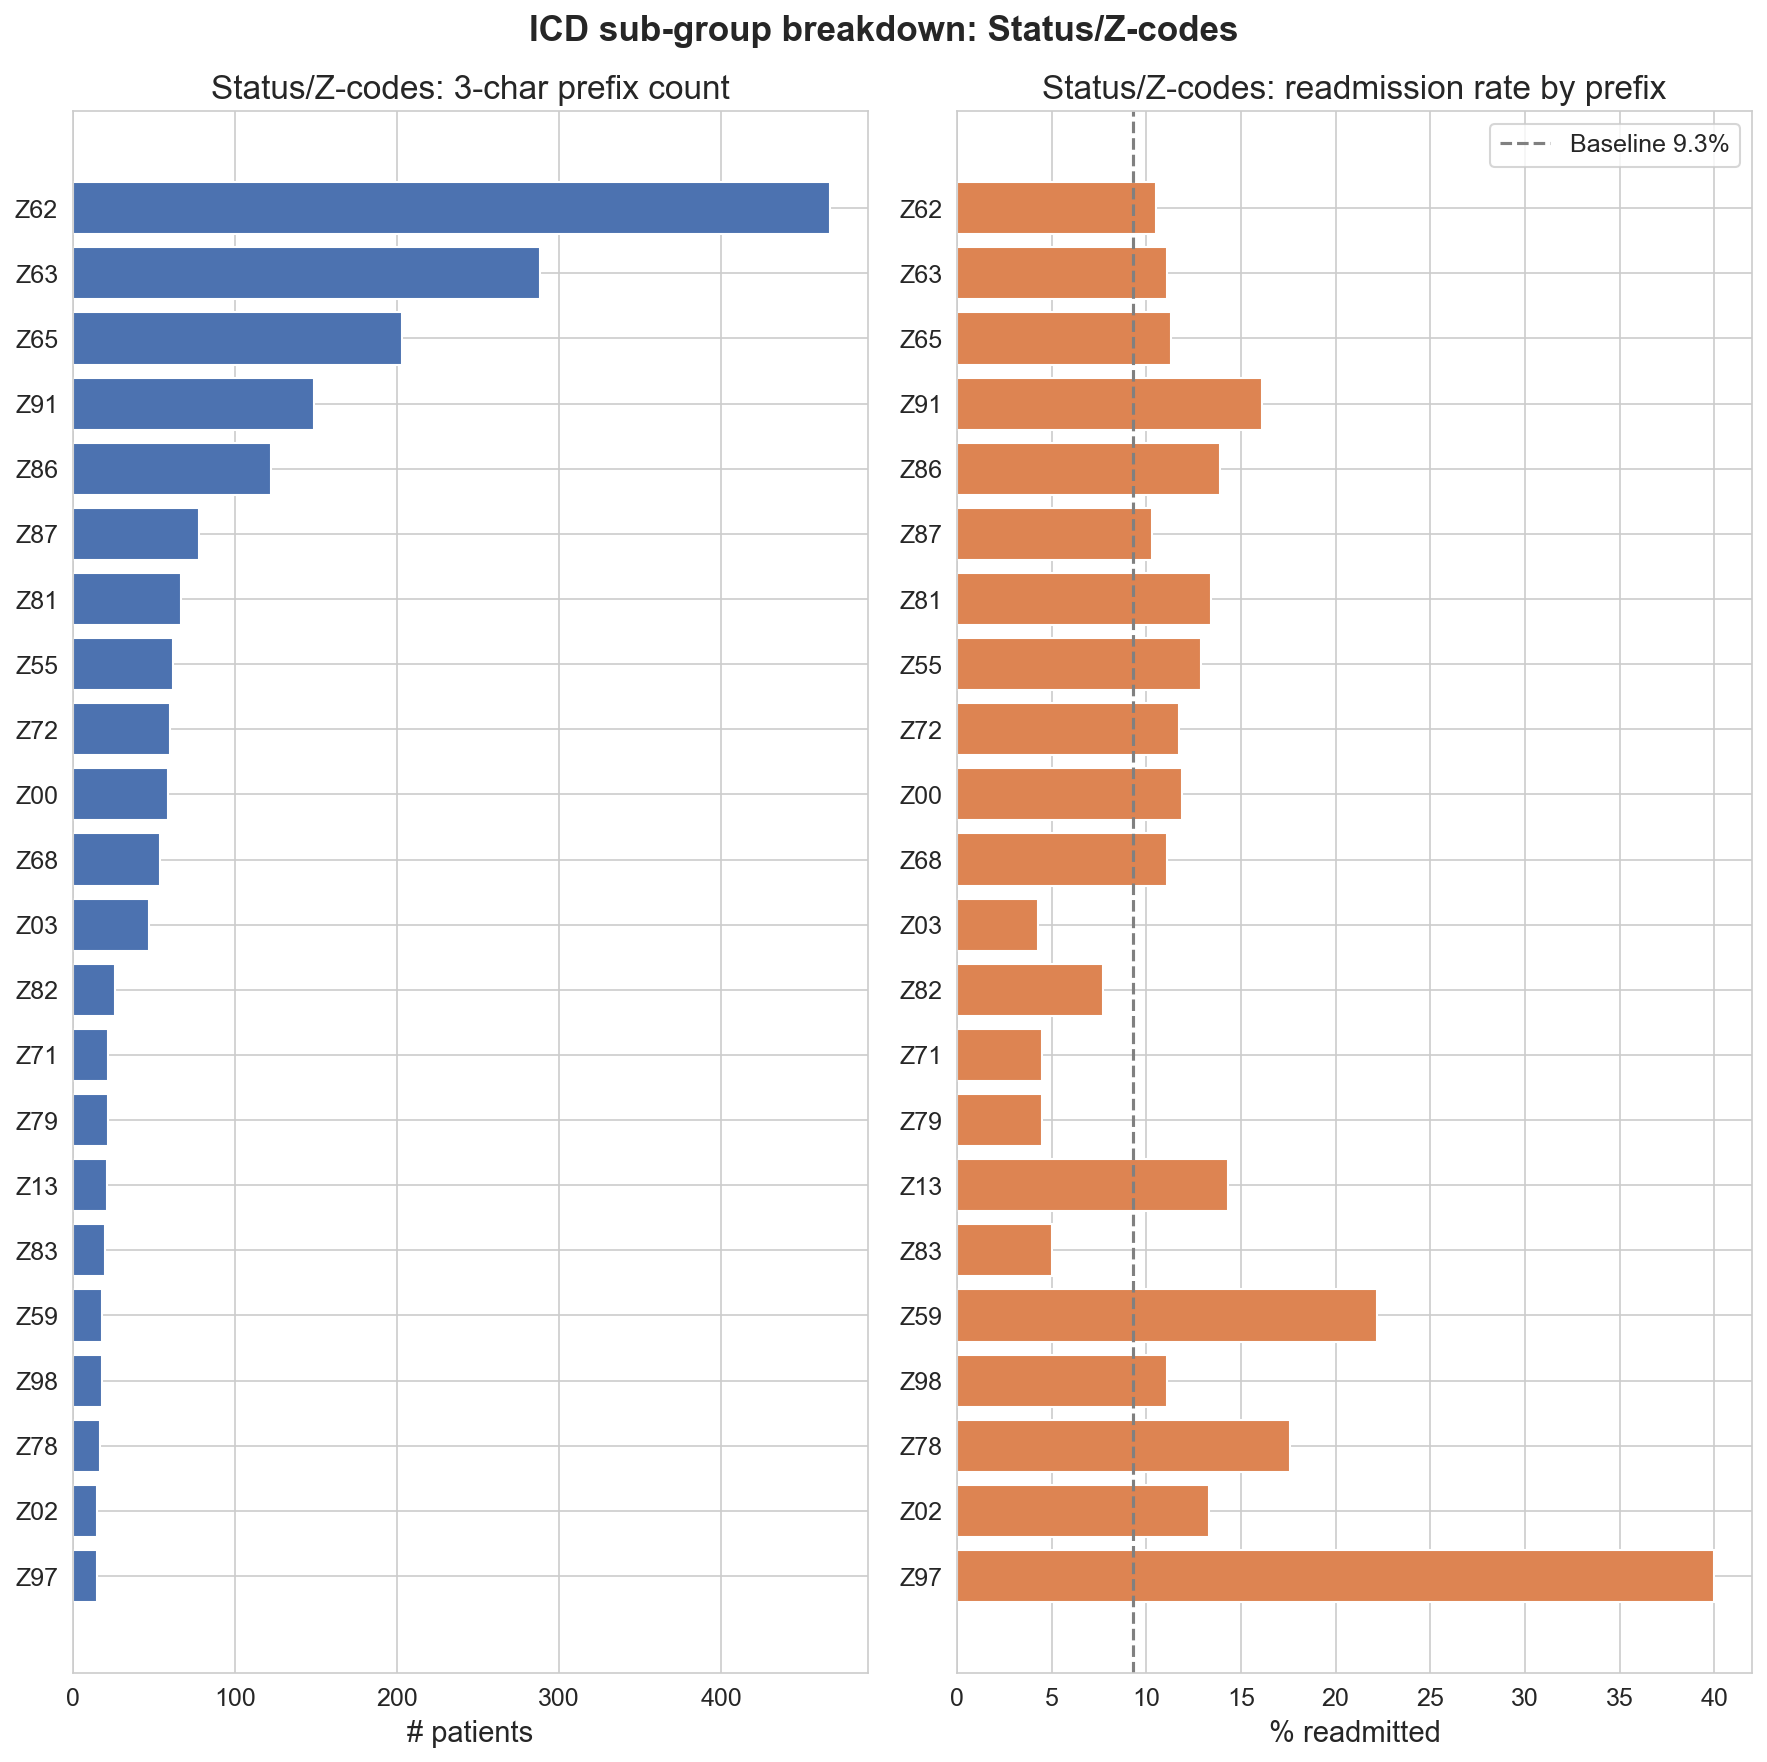

prefix   n  readmit_pct
   Z62 467         10.5
   Z63 288         11.1
   Z65 203         11.3
   Z91 149         16.1
   Z86 122         13.9
   Z87  78         10.3
   Z81  67         13.4
   Z55  62         12.9
   Z72  60         11.7
   Z00  59         11.9
   Z68  54         11.1
   Z03  47          4.3
   Z82  26          7.7
   Z71  22          4.5
   Z79  22          4.5
   Z13  21         14.3
   Z83  20          5.0
   Z59  18         22.2
   Z98  18         11.1
   Z78  17         17.6
   Z02  15         13.3
   Z97  15         40.0


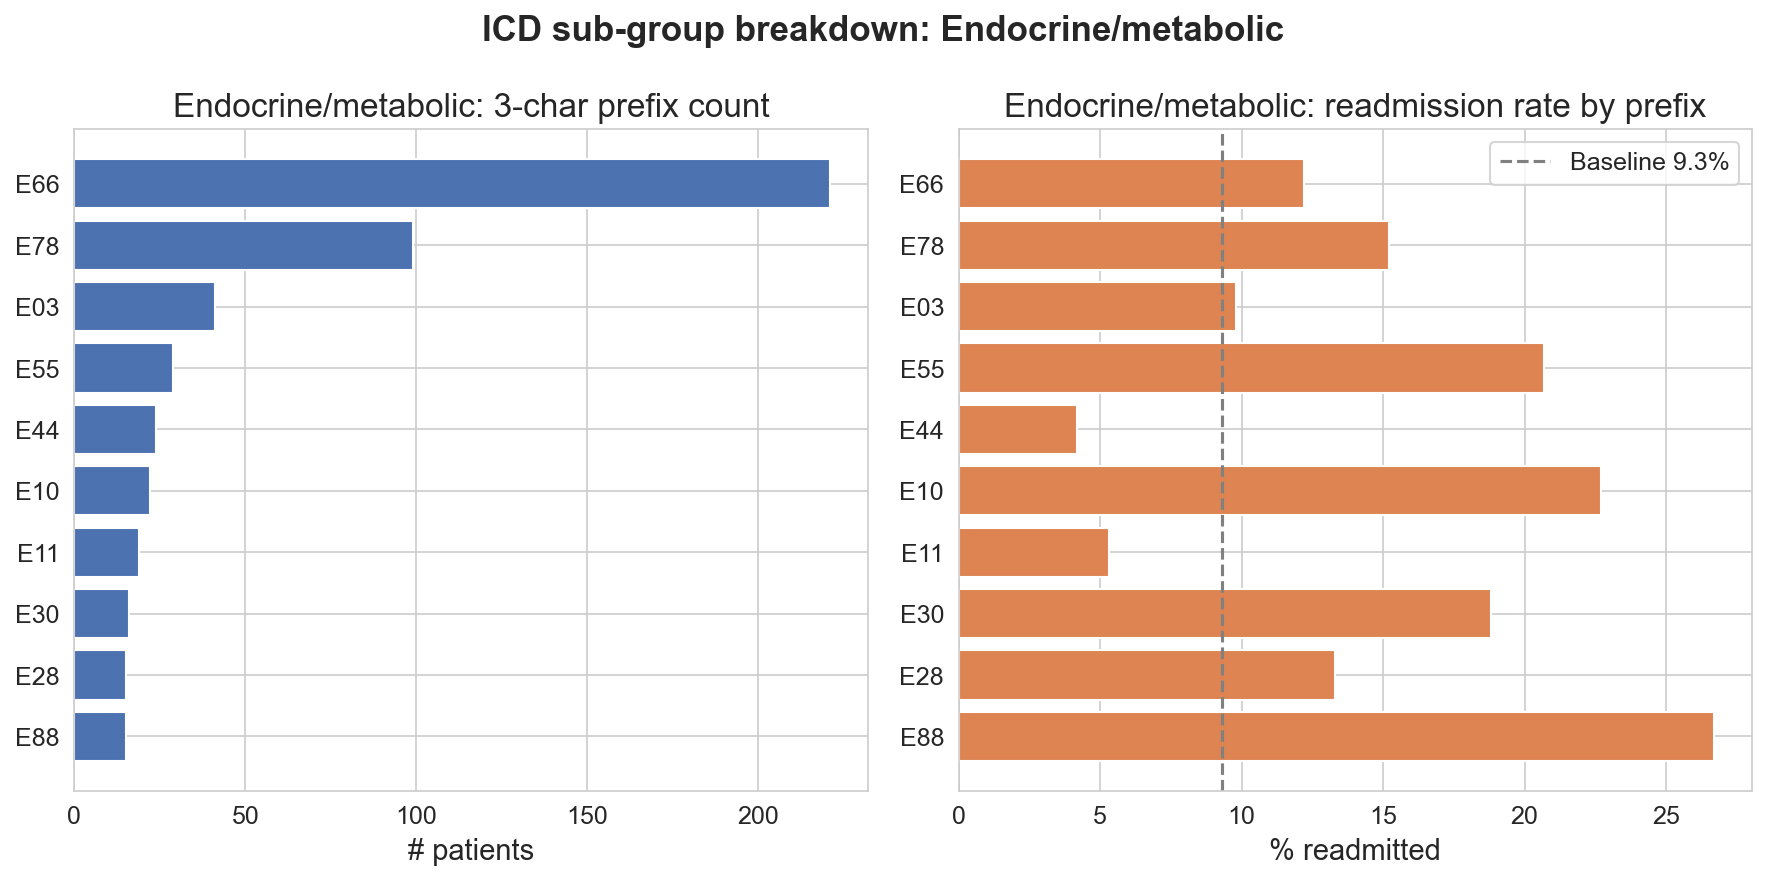

prefix   n  readmit_pct
   E66 221         12.2
   E78  99         15.2
   E03  41          9.8
   E55  29         20.7
   E44  24          4.2
   E10  22         22.7
   E11  19          5.3
   E30  16         18.8
   E28  15         13.3
   E88  15         26.7


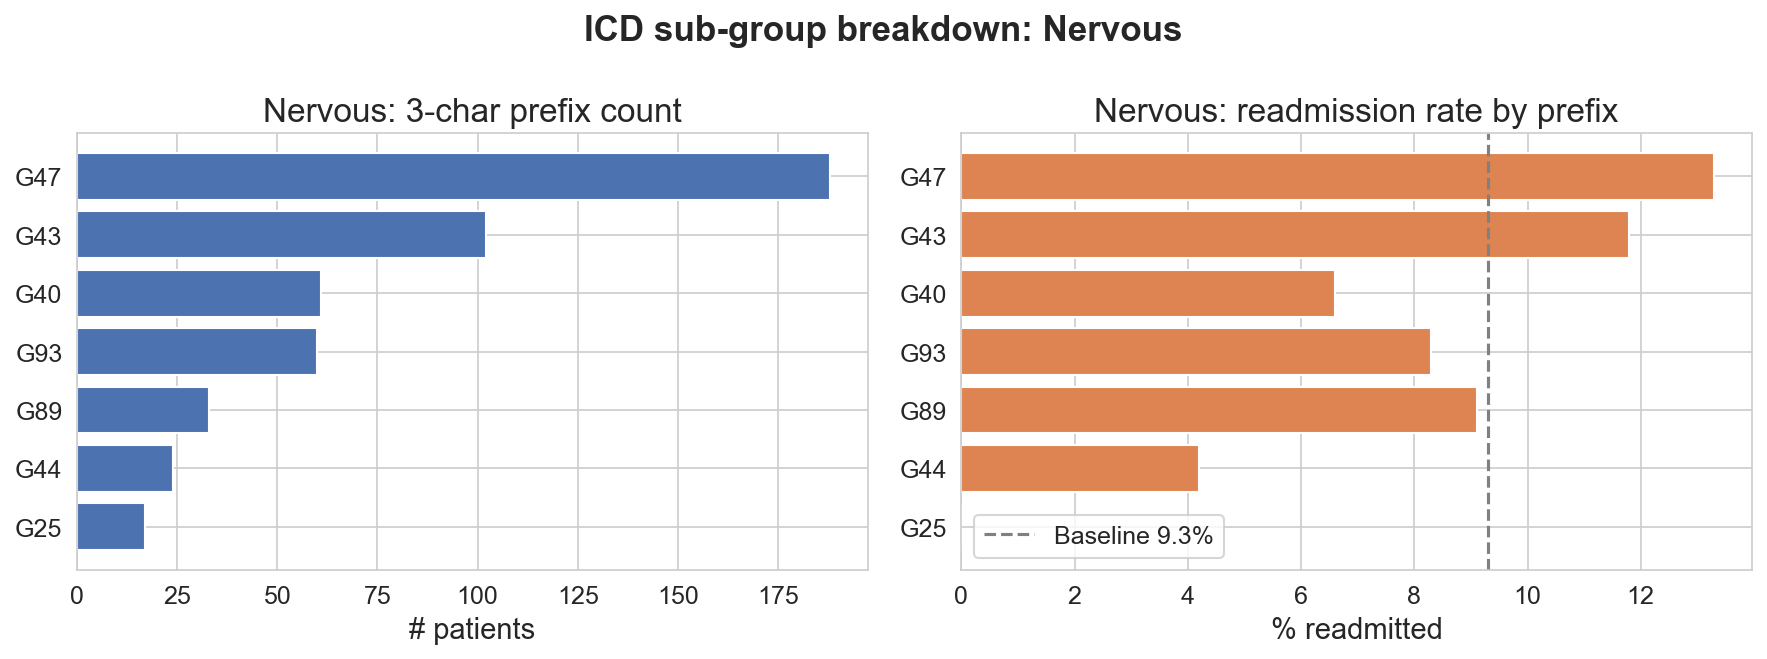

prefix   n  readmit_pct
   G47 188         13.3
   G43 102         11.8
   G40  61          6.6
   G93  60          8.3
   G89  33          9.1
   G44  24          4.2
   G25  17          0.0


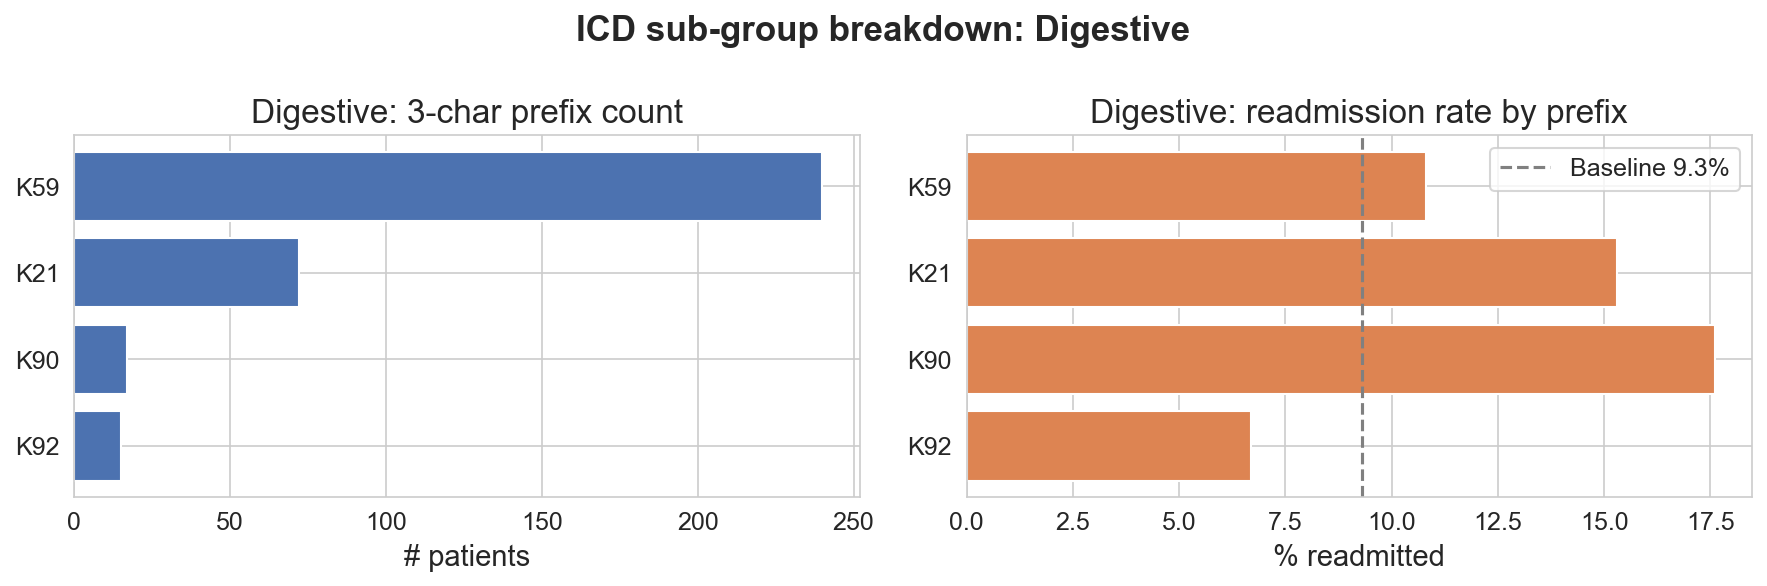

prefix   n  readmit_pct
   K59 240         10.8
   K21  72         15.3
   K90  17         17.6
   K92  15          6.7


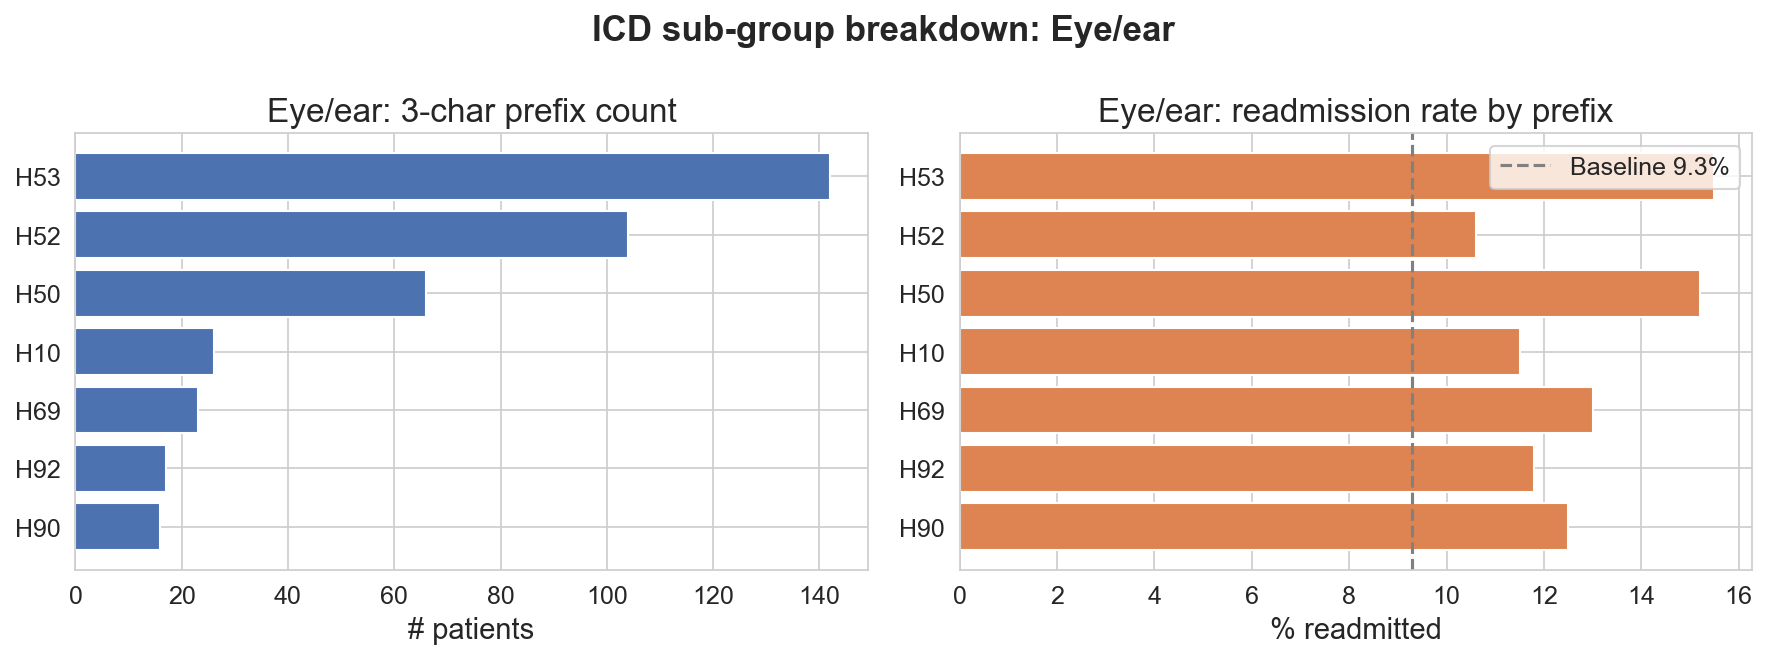

prefix   n  readmit_pct
   H53 142         15.5
   H52 104         10.6
   H50  66         15.2
   H10  26         11.5
   H69  23         13.0
   H92  17         11.8
   H90  16         12.5


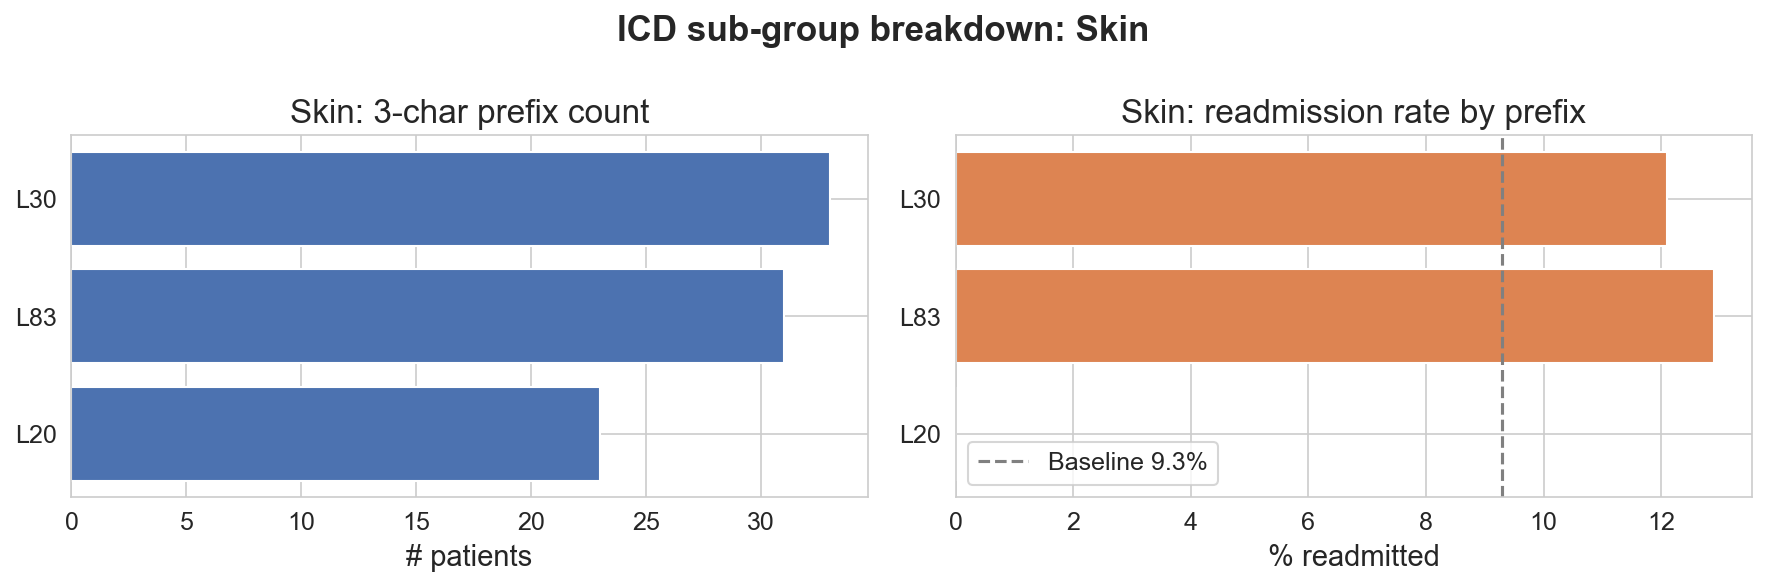

prefix  n  readmit_pct
   L30 33         12.1
   L83 31         12.9
   L20 23          0.0


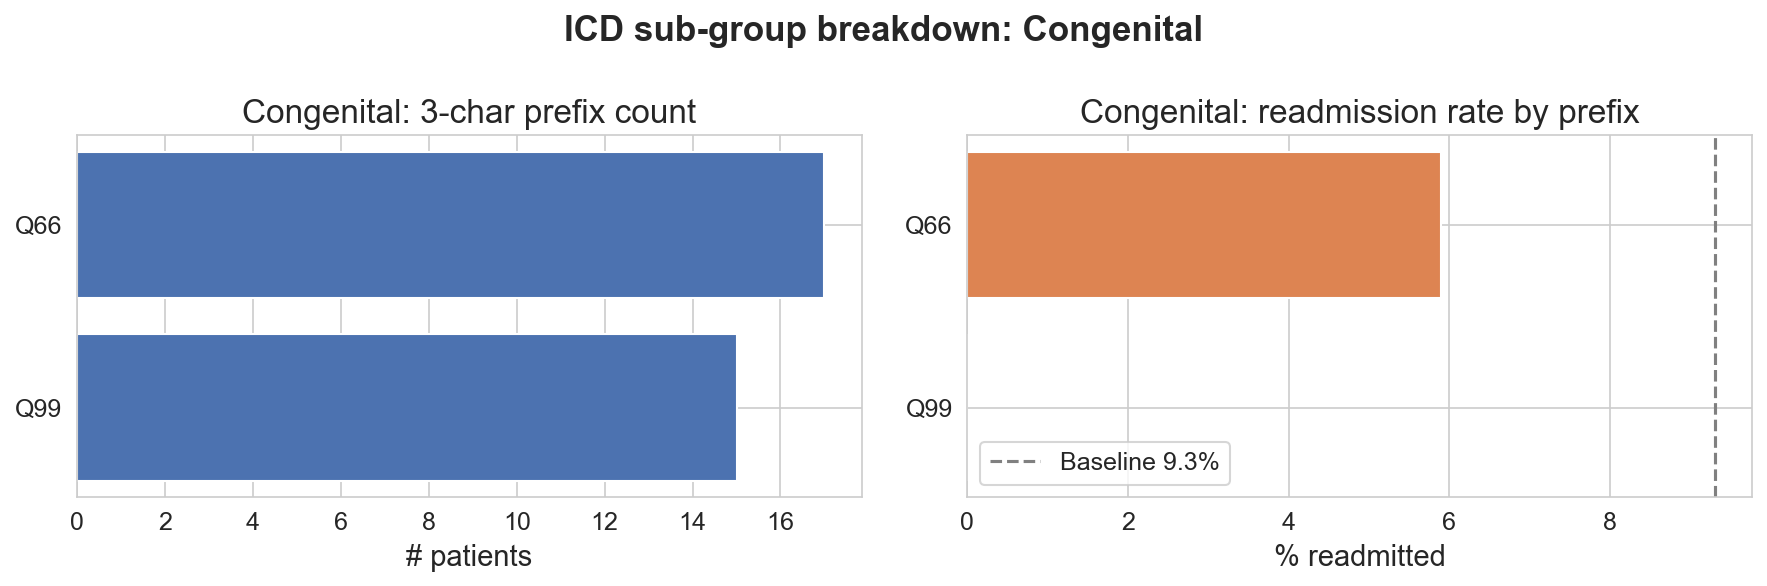

prefix  n  readmit_pct
   Q66 17          5.9
   Q99 15          0.0


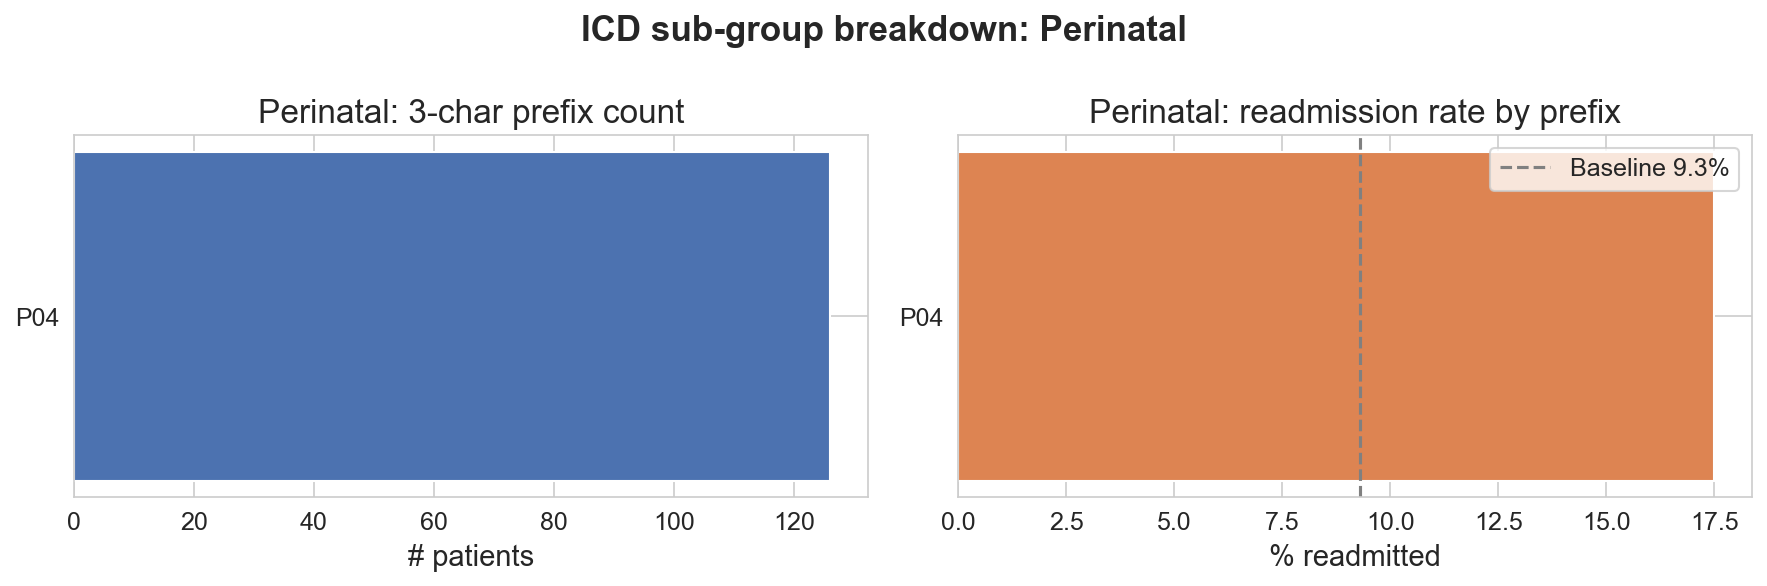

prefix   n  readmit_pct
   P04 126         17.5
Blood/neoplasm: no sub-group with n>=15


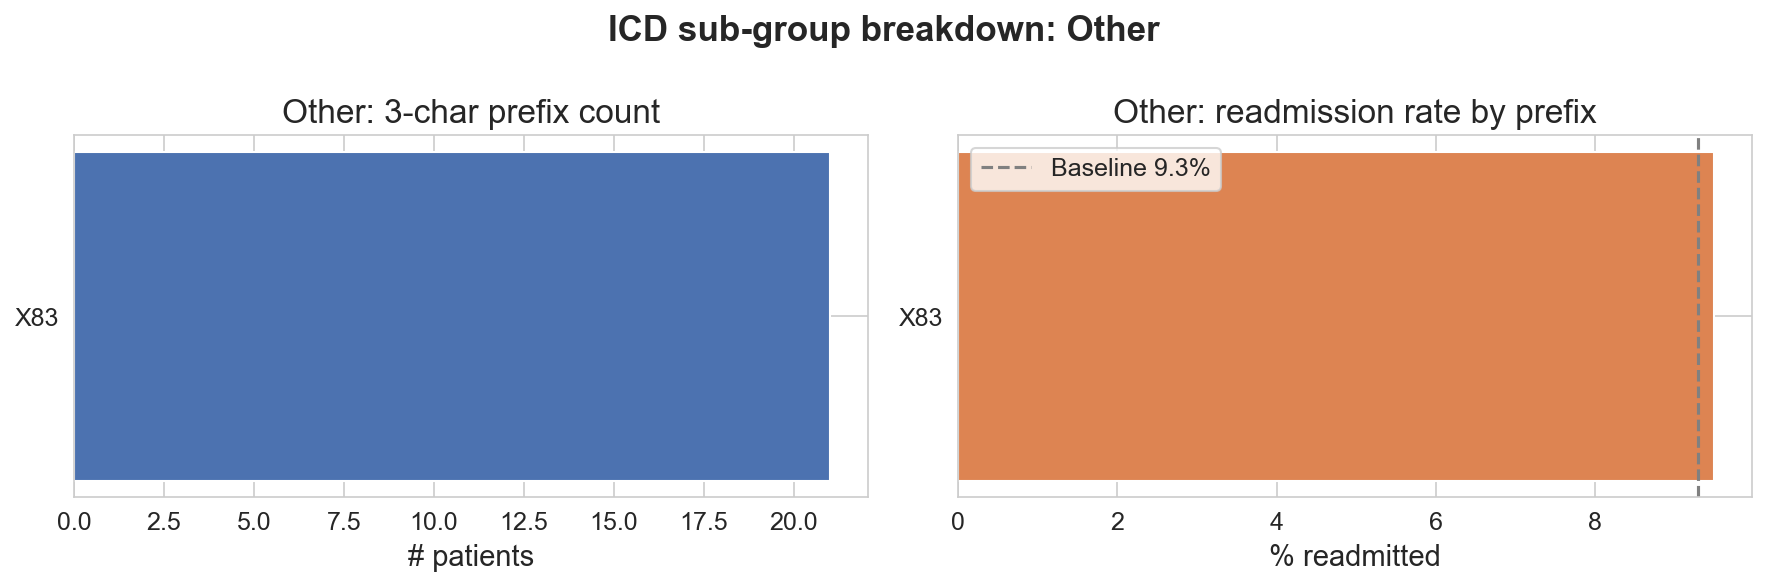

prefix  n  readmit_pct
   X83 21          9.5


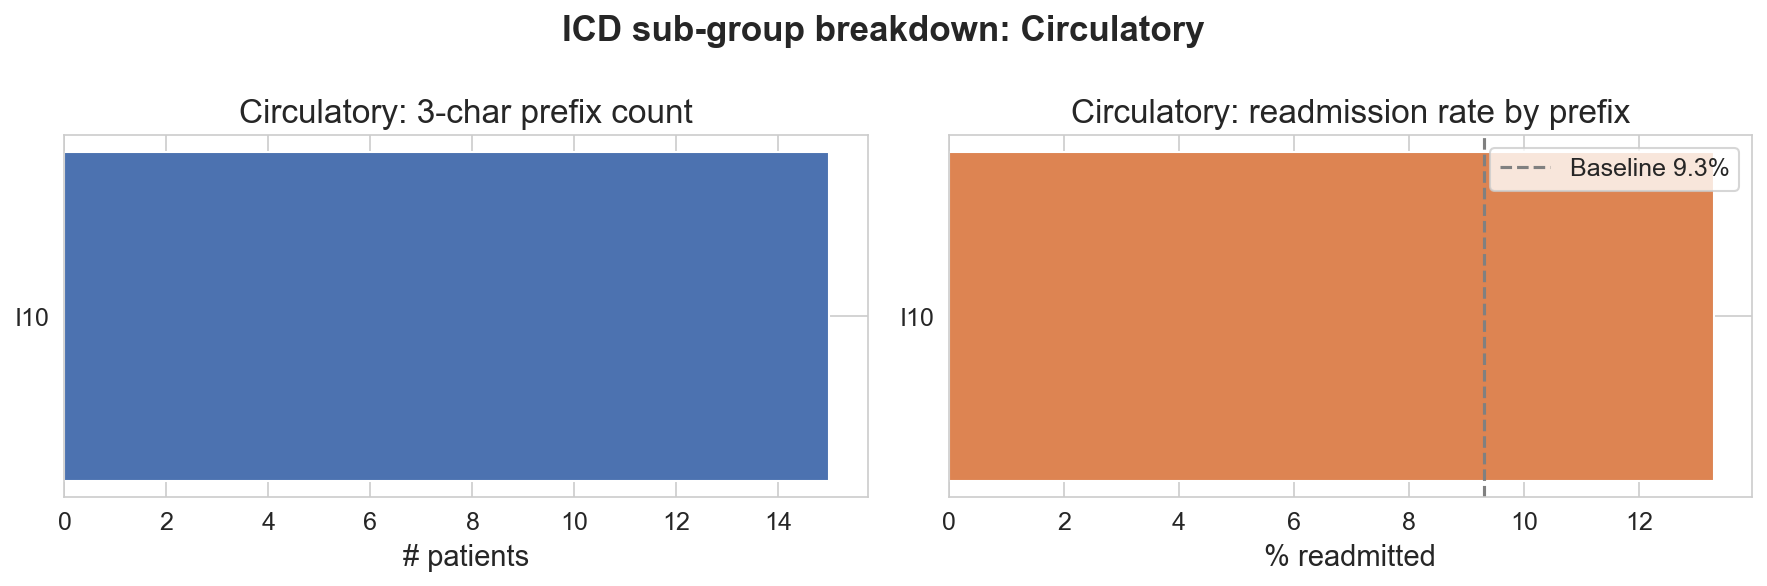

prefix  n  readmit_pct
   I10 15         13.3


In [18]:
# ICD-10 chapter breakdown: prevalence + readmission rate per chapter (complements the DSM-5 breakdown)
from collections import Counter
cc=Counter(ch for s in df['_icd_chapters'] for ch in s)
rows=[dict(chapter=ch,n=int(n),pct=round(n/len(df)*100,1),readmit_pct=round(df[df['_icd_chapters'].apply(lambda s: ch in s)]['readmitted'].mean()*100,1)) for ch,n in cc.items() if n>=30]
icd=pd.DataFrame(rows).sort_values('n',ascending=False); icd.to_csv('figures/P1_icd_chapters.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].barh(icd['chapter'],icd['pct'],color='#4C72B0'); ax[0].set_xlabel('% of patients'); ax[0].set_title('ICD-10 chapter prevalence'); ax[0].invert_yaxis()
ax[1].barh(icd['chapter'],icd['readmit_pct'],color='#DD8452'); ax[1].axvline(9.3,color='gray',ls='--'); ax[1].set_xlabel('% readmitted'); ax[1].set_title('Readmission rate by ICD chapter'); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig('figures/P1_icd_chapters.png',dpi=150); plt.show()
print(icd.to_string(index=False))

# ── Sub-group breakdown for above-baseline ICD chapters ────────────────────────
BASELINE = 9.3
above_bl = icd[icd['readmit_pct'] > BASELINE]['chapter'].tolist()
_CH_LETTER = {v: k for k, v in _ICD_CH.items()}  # invert chapter-name → letter map

def _build_prefix_table(df_data, ch_letter):
    """One-pass: collect (patient_idx, 3-char prefix) for the given chapter.
    ch_letter=None means 'Other' (letters not in _ICD_CH, e.g. V/W/X/Y)."""
    combined = (df_data['VisitDiags'].fillna('') + ',' +
                df_data['NonSuicidialDiags'].fillna('') + ',' +
                df_data['ChronicDiags'].fillna(''))
    records = []
    for idx, code_str in combined.items():
        seen = set()
        for tok in code_str.split(','):
            tok = tok.strip().upper()
            if not tok:
                continue
            if ch_letter is not None:
                if tok[0] == ch_letter:
                    seen.add(tok[:3])
            else:
                if tok[0] not in _ICD_CH:
                    seen.add(tok[:3])
        for pfx in seen:
            records.append((idx, pfx))
    if not records:
        return pd.DataFrame(columns=['idx', 'prefix'])
    return pd.DataFrame(records, columns=['idx', 'prefix'])

for chapter_name in above_bl:
    ch_letter = _CH_LETTER.get(chapter_name)  # None for 'Other' (V/W/X/Y)
    pfx_df = _build_prefix_table(df, ch_letter)
    if pfx_df.empty:
        print(f'{chapter_name}: no codes found'); continue
    sub_rows = []
    for pfx, grp in pfx_df.groupby('prefix'):
        idxs = grp['idx'].values
        n = len(idxs)
        if n < 15:
            continue
        ra_rate = df.loc[idxs, 'readmitted'].mean() * 100
        sub_rows.append({'prefix': pfx, 'n': n, 'readmit_pct': round(ra_rate, 1)})
    if not sub_rows:
        print(f'{chapter_name}: no sub-group with n>=15'); continue
    sub_df = pd.DataFrame(sub_rows).sort_values('n', ascending=False)
    safe_name = chapter_name.replace('/', '_').replace(' ', '_')
    sub_df.to_csv(f'figures/P1_icd_subgroups_{safe_name}.csv', index=False)
    fig2, axs2 = plt.subplots(1, 2, figsize=(12, max(4, len(sub_df) * 0.5 + 1)))
    axs2[0].barh(sub_df['prefix'], sub_df['n'], color='#4C72B0')
    axs2[0].set_xlabel('# patients'); axs2[0].set_title(f'{chapter_name}: 3-char prefix count')
    axs2[0].invert_yaxis()
    axs2[1].barh(sub_df['prefix'], sub_df['readmit_pct'], color='#DD8452')
    axs2[1].axvline(BASELINE, color='gray', ls='--', label=f'Baseline {BASELINE}%')
    axs2[1].set_xlabel('% readmitted'); axs2[1].set_title(f'{chapter_name}: readmission rate by prefix')
    axs2[1].invert_yaxis(); axs2[1].legend()
    plt.suptitle(f'ICD sub-group breakdown: {chapter_name}', fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'figures/P1_icd_subgroups_{safe_name}.png', dpi=150)
    plt.show()
    print(sub_df.to_string(index=False))


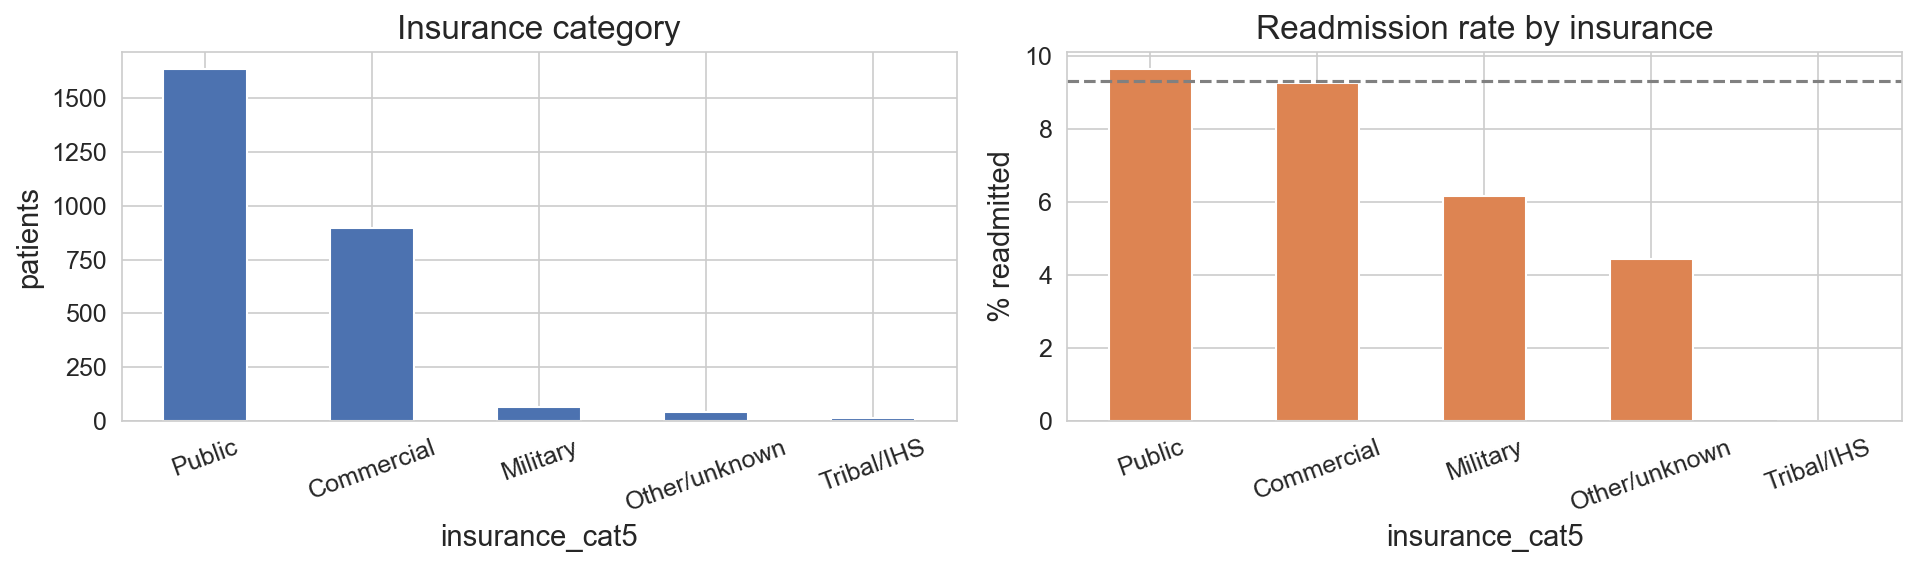

                   n  readmit_pct  LOS_median  ACE_median  highACE_pct
insurance_cat5                                                        
Commercial       896          9.3         8.0         2.0         29.4
Military          65          6.2         8.0         2.0         27.7
Other/unknown     45          4.4         7.0         2.5         22.2
Public          1631          9.6         9.0         4.0         43.1
Tribal/IHS        15          0.0         9.0         5.0         13.3

Military (n=65) vs Commercial LOS: medians 8 vs 8, MWU p=0.411
NOTE: Tribal/IHS (n=15) and Military (n=65) are small groups — descriptive/exploratory only.


In [19]:
# Insurance breakdown (Public/Commercial/Military/Tribal-IHS/Other) + military & tribal comparisons
from scipy import stats as _st
ic=df['insurance_cat5'].value_counts()
fig,ax=plt.subplots(1,2,figsize=(13,4))
ic.plot.bar(ax=ax[0],color='#4C72B0'); ax[0].set_title('Insurance category'); ax[0].set_ylabel('patients'); ax[0].tick_params(axis='x',rotation=20)
df.groupby('insurance_cat5')['readmitted'].mean().mul(100).reindex(ic.index).plot.bar(ax=ax[1],color='#DD8452')
ax[1].axhline(9.3,color='gray',ls='--'); ax[1].set_title('Readmission rate by insurance'); ax[1].set_ylabel('% readmitted'); ax[1].tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.savefig('figures/P1_insurance.png',dpi=150); plt.show()
tab=df.groupby('insurance_cat5').agg(n=('readmitted','size'),readmit_pct=('readmitted',lambda s: round(s.mean()*100,1)),
    LOS_median=('los_days','median'),ACE_median=('ace_score','median'),highACE_pct=('high_ace_expanded',lambda s: round(s.fillna(0).mean()*100,1)))
tab.to_csv('figures/P1_insurance_breakdown.csv'); print(tab.to_string())
_mil=df[df.insurance_cat5=='Military']['los_days'].dropna(); _com=df[df.insurance_cat5=='Commercial']['los_days'].dropna()
print('\nMilitary (n=%d) vs Commercial LOS: medians %.0f vs %.0f, MWU p=%.3f'%(len(_mil),_mil.median(),_com.median(),_st.mannwhitneyu(_mil,_com,alternative='two-sided')[1]))
print('NOTE: Tribal/IHS (n=%d) and Military (n=%d) are small groups — descriptive/exploratory only.'%((df.insurance_cat5=='Tribal/IHS').sum(),(df.insurance_cat5=='Military').sum()))